# MiniNet-Opt
## Conception, entraînement, régularisation et optimisation sous contraintes d'un réseau de neurones

**Projet intégrateur, Optimisation pour le Machine Learning**
BAKO Ange Stève Hakira, 20230516

Ce notebook est le rapport du projet. Les tableaux et figures sont relus depuis le dossier `results/`, produit par les notebooks 01 à 09. Le notebook se lit sans rien réentraîner : seule la vérification des gradients (section 3) est recalculée.

In [1]:
import os, sys, numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
sys.path.append('..')
from src.data import load_data
from src.model import MLP
from src.losses import bce

RES = '../results'

def show_fig(name, width=900):
    # cherche la figure dans results/figures puis dans results
    for d in [os.path.join(RES, 'figures'), RES]:
        p = os.path.join(d, name)
        if os.path.exists(p):
            display(Image(filename=p, width=width)); return
    display(Markdown(f'*Figure `{name}` introuvable : exécuter le notebook qui la produit.*'))

def show_csv(name, index_col=0, decimals=4):
    p = os.path.join(RES, name)
    if not os.path.exists(p):
        display(Markdown(f'*Tableau `{name}` introuvable : exécuter le notebook qui le produit.*')); return None
    df = pd.read_csv(p, index_col=index_col)
    display(df if decimals is None else df.round(decimals))
    return df

data = load_data(seed=42)

## 1. Introduction et problème étudié

Entraîner un réseau de neurones revient à résoudre un problème d'optimisation sur ses paramètres $\theta = (W^{(1)}, b^{(1)}, \dots, W^{(L)}, b^{(L)})$ :

$$\min_\theta F_{train}(\theta) = \frac{1}{n} \sum_{i=1}^{n} \ell\big(f_\theta(x_i), y_i\big).$$

Le projet enrichit ce problème en trois étapes. On l'optimise d'abord tel quel avec plusieurs méthodes de gradient. On contrôle ensuite la généralisation par une pénalité, $\min_\theta F_{train}(\theta) + \lambda\,\Omega(\theta)$, et par d'autres techniques de régularisation. On impose enfin une contrainte explicite, $\min_\theta F_{train}(\theta)$ sous $\theta \in C$, résolue par gradient projeté.

Le réseau, la rétropropagation et les optimiseurs sont écrits en NumPy, sans différentiation automatique. PyTorch sert uniquement à vérifier les résultats à la fin.

## 2. Données et architecture du réseau

**Données.** Le jeu `make_moons` compte 1 500 points en dimension 2 (bruit 0.20, graine 42), répartis en deux classes en forme de croissants imbriqués. Il est découpé en 60 % train, 20 % validation et 20 % test, soit 900, 300 et 300 points, avec la même proportion de chaque classe dans les trois ensembles. Les variables sont standardisées avec la moyenne et l'écart-type du **seul** jeu d'entraînement, pour que la validation et le test n'influencent rien.

In [2]:
print({k: v.shape for k, v in data.items()})
m = MLP(seed=0)
n_params = m.get_params().size
n_weights = sum(l.W.size for l in m.linear_layers())
print(f'Nombre de paramètres : {n_params} (dont {n_weights} poids W et {n_params - n_weights} biais)')

{'X_train': (900, 2), 'y_train': (900, 1), 'X_val': (300, 2), 'y_val': (300, 1), 'X_test': (300, 2), 'y_test': (300, 1), 'mu': (2,), 'sigma': (2,)}
Nombre de paramètres : 193 (dont 168 poids W et 25 biais)


**Architecture.** Le réseau suit l'architecture de référence $2 \to 16 \to 8 \to 1$ : deux couches cachées avec ReLU, une sortie sigmoïde. Il a 193 paramètres, dont 168 poids et 25 biais. Pour une entrée $x$ :

$$z^{(1)} = W^{(1)}x + b^{(1)},\quad a^{(1)} = \mathrm{ReLU}(z^{(1)}),$$
$$z^{(2)} = W^{(2)}a^{(1)} + b^{(2)},\quad a^{(2)} = \mathrm{ReLU}(z^{(2)}),$$
$$z^{(3)} = W^{(3)}a^{(2)} + b^{(3)},\quad \hat y = \sigma(z^{(3)}) = \frac{1}{1 + e^{-z^{(3)}}}.$$

**Perte.** On utilise la binary cross-entropy $\ell(\hat y, y) = -y\log\hat y - (1-y)\log(1-\hat y)$, moyennée sur le mini-batch.

**Organisation du code.** `data.py` (génération, split, standardisation), `layers.py` (Linear, ReLU, Sigmoid, Dropout), `model.py` (assemblage), `losses.py` (BCE), `optimizers.py` (SGD, Momentum, Adam), `regularization.py` (pénalité $L^2$, early stopping), `constraints.py` (norme, projection, gradient projeté), `train.py` (boucle d'entraînement).

## 3. Propagation avant et rétropropagation

**Dérivées des activations.** $\mathrm{ReLU}'(z) = \mathbb{1}_{z > 0}$ et $\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big)$.

**Gradient par rapport à la sortie.** En composant la BCE et la sigmoïde, les termes se simplifient :

$$\frac{\partial \ell}{\partial z^{(3)}} = \frac{\partial \ell}{\partial \hat y}\,\sigma'(z^{(3)}) = \frac{\hat y - y}{\hat y(1-\hat y)}\,\hat y(1-\hat y) = \hat y - y.$$

Pour un mini-batch de taille $m$, on note $\delta^{(3)} = \frac{1}{m}(\hat y - y)$.

**Relations récursives.** Pour une couche cachée $\ell$, on propage le gradient de la couche suivante, puis on multiplie composante par composante ($\odot$) par la dérivée de l'activation :

$$\delta^{(\ell)} = \big(W^{(\ell+1)\top}\delta^{(\ell+1)}\big) \odot \mathbb{1}_{z^{(\ell)} > 0}.$$

**Gradients des poids et des biais.** Avec $a^{(0)} = x$ et une somme sur les exemples du mini-batch :

$$\frac{\partial F}{\partial W^{(\ell)}} = \sum_{i} \delta^{(\ell)}_i\, a^{(\ell-1)\top}_i, \qquad \frac{\partial F}{\partial b^{(\ell)}} = \sum_i \delta^{(\ell)}_i.$$

Le forward stocke $z^{(\ell)}$ et $a^{(\ell)}$, que le backward réutilise.

**Vérification par différences finies.** Pour chaque composante, $\frac{\partial F}{\partial \theta_j} \approx \frac{F(\theta + \varepsilon e_j) - F(\theta - \varepsilon e_j)}{2\varepsilon}$ avec $\varepsilon = 10^{-5}$. On compare au gradient analytique avec l'erreur relative $\frac{\|g_a - g_n\|}{\|g_a\| + \|g_n\| + \varepsilon}$. La cellule suivante refait ce calcul sur les 193 paramètres, pour 5 initialisations.

In [3]:
rows = []
X40, y40 = data['X_train'][:40], data['y_train'][:40]
for s in range(5):
    m = MLP(seed=s); m.eval()
    m.loss_and_grad(X40, y40); g_a = m.get_grads().copy()
    theta = m.get_params().copy(); g_n = np.zeros_like(theta)
    for j in range(theta.size):
        e = np.zeros_like(theta); e[j] = 1e-5
        m.set_params(theta + e); fp = bce(m.forward(X40), y40)
        m.set_params(theta - e); fm = bce(m.forward(X40), y40)
        g_n[j] = (fp - fm) / 2e-5
    m.set_params(theta)
    rows.append({'seed': s, 'erreur relative': np.linalg.norm(g_a - g_n) / (np.linalg.norm(g_a) + np.linalg.norm(g_n) + 1e-5)})
pd.DataFrame(rows).set_index('seed').style.format('{:.1e}')

,erreur relative
seed,
0,3.2e-11
1,4.6e-11
2,2.5e-11
3,3.1e-11
4,2.5e-11


L'erreur relative est de l'ordre de $10^{-11}$, très en dessous du seuil habituel de $10^{-7}$ : la rétropropagation est correcte. Le jalon J1 est validé. La section 8.5 confirme ce résultat par une méthode indépendante, en comparant les gradients à ceux d'autograd (PyTorch), qui coïncident à $5 \cdot 10^{-16}$ près.

## 4. Méthodes d'optimisation

À l'itération $k$, on calcule le gradient sur un mini-batch $B_k$ de 32 exemples, $g_k = \nabla F_{B_k}(\theta_k)$. Les opérations sur les vecteurs se font composante par composante.

**SGD.** $\theta_{k+1} = \theta_k - \alpha g_k$.

**Momentum.** $v_{k+1} = \beta v_k + (1-\beta) g_k$, puis $\theta_{k+1} = \theta_k - \alpha v_{k+1}$, avec $\beta = 0.9$ et $v_0 = 0$. La moyenne mobile des gradients atténue les oscillations et accélère la progression dans les directions stables.

**Adam.** $m_k = \beta_1 m_{k-1} + (1-\beta_1) g_k$ et $v_k = \beta_2 v_{k-1} + (1-\beta_2) g_k^2$. On corrige ensuite le biais d'initialisation, $\hat m_k = m_k / (1-\beta_1^k)$ et $\hat v_k = v_k / (1-\beta_2^k)$, et on fait le pas $\theta_{k+1} = \theta_k - \alpha\, \hat m_k / (\sqrt{\hat v_k} + \varepsilon)$, avec $\beta_1 = 0.9$, $\beta_2 = 0.999$ et $\varepsilon = 10^{-8}$. Chaque composante a donc son propre pas effectif.

## 5. Régularisation et protocole de généralisation

**Pénalité $L^2$.** On minimise $F_\lambda(\theta) = F_{train}(\theta) + \frac{\lambda}{2}\sum_\ell \|W^{(\ell)}\|_F^2$, sans pénaliser les biais. Le gradient devient $\nabla_{W^{(\ell)}} F_\lambda = \nabla_{W^{(\ell)}} F_{train} + \lambda W^{(\ell)}$. Ce gradient a été vérifié par différences finies (erreur relative de l'ordre de $10^{-10}$). On teste $\lambda \in \{0, 10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$.

**Dropout.** Pendant l'entraînement, chaque activation cachée est gardée avec une probabilité $p$ : $M_j \sim \mathrm{Bernoulli}(p)$ et $\tilde h_j = \frac{M_j}{p} h_j$. La division par $p$ conserve l'espérance des activations, ce qui permet de désactiver le dropout en validation et en test sans changer l'échelle. Le taux de dropout vaut $1 - p$, testé dans $\{0.1, 0.2, 0.3, 0.5\}$.

**Early stopping.** Après chaque époque, on calcule la loss de validation et on sauvegarde les meilleurs paramètres. On arrête après $P$ époques sans amélioration, puis on restaure les meilleurs paramètres. La patience est fixée à l'avance à $P = 20$. La choisir sur la validation avantagerait mécaniquement les grandes valeurs, puisque la meilleure loss est alors un minimum pris sur plus d'époques.

**Protocole de sélection (jalon J3).** Il a été fixé avant toute utilisation du jeu de test :

1. le split et la standardisation sont fixés une fois pour toutes ;
2. l'architecture, l'optimiseur, le learning rate et le budget d'entraînement sont choisis sans le test ;
3. $\lambda$ et le taux de dropout sont retenus par la plus faible loss de validation moyenne sur 5 seeds ;
4. le modèle final est celui qui a la plus faible loss de validation parmi les quatre cas comparés ;
5. les modèles retenus sont réentraînés et évalués **une seule fois** sur le test, après avoir vérifié qu'ils redonnent exactement les loss de validation de la sélection.

## 6. Formulation sous contrainte et gradient projeté

On remplace la pénalité par une contrainte explicite :

$$\min_\theta F_{train}(\theta) \quad \text{s.c.} \quad \|\theta\|_2 \le R, \qquad \text{avec } \|\theta\|_2^2 = \sum_\ell \|W^{(\ell)}\|_F^2 \text{ (biais exclus)}.$$

**Projection.** Sur la boule $C = \{\theta : \|\theta\|_2 \le R\}$, la projection euclidienne a une forme explicite : $P_C(z) = z$ si $\|z\|_2 \le R$, et $P_C(z) = R\,z/\|z\|_2$ sinon. Elle ramène radialement sur le bord tout point extérieur.

**Gradient projeté.** On fait un pas de gradient, $\tilde\theta_{k+1} = \theta_k - \alpha \nabla F_{B_k}(\theta_k)$, puis on projette : $\theta_{k+1} = P_C(\tilde\theta_{k+1})$. Chaque itéré est donc admissible.

**Faisabilité et activité.** À la fin de l'entraînement, on calcule $\|\theta^\star\|_2$ et le résidu de faisabilité $r_{feas} = \max(0, \|\theta^\star\|_2 - R)$. La contrainte est dite active si $|\,\|\theta^\star\|_2 - R\,| \le \varepsilon$, avec $\varepsilon = 10^{-3} R$.

**Lien avec la pénalité.** Le lagrangien de la contrainte s'écrit $F_{train}(\theta) + \frac{\mu}{2}(\|\theta\|_2^2 - R^2)$. En un point KKT où la contrainte est active, $\nabla F_{train}(\theta^\star) + \mu\,\theta^\star = 0$ avec $\mu \ge 0$. C'est exactement la condition de stationnarité du problème pénalisé avec $\lambda = \mu$. Dans un problème convexe, les deux formulations ont donc les mêmes solutions pour le bon couple $(\lambda, R)$. Ici, le problème n'est pas convexe : cette correspondance est vérifiée expérimentalement en section 8.4. On estime $\mu$ en fin d'entraînement par $\mu = -\langle \nabla_W F, W\rangle / \|W\|^2$.

## 7. Protocole expérimental

Toutes les comparaisons respectent les mêmes règles. Le split est le même pour toutes les expériences et l'architecture ne change pas. Chaque expérience est répétée sur les seeds 0 à 4, qui fixent l'initialisation des poids et l'ordre des mini-batchs. Deux méthodes comparées avec la même seed partent donc du même point et voient les mêmes données dans le même ordre. L'initialisation ne dépend pas du dropout, pour que la comparaison reste équitable. Les résultats sont donnés en moyenne et écart-type sur les 5 seeds.

Les budgets sont de 100 époques pour la comparaison des optimiseurs (partie C) et de 500 époques à partir de la partie D, durée nécessaire pour que le sur-apprentissage apparaisse nettement. Le batch compte 32 exemples. Les hyperparamètres sont choisis sur la validation uniquement. Le jeu de test n'est consulté qu'à la fin de D2 et de F1, une seule fois, sans qu'aucun choix ne soit modifié ensuite.

## 8. Résultats

### 8.1 Comparaison des optimiseurs (parties C, jalon J2)

Chaque optimiseur est testé sur une grille de learning rates (100 époques, 5 seeds). Le tableau complet est lu dans `c2_aggregated.csv`.

In [4]:
show_csv('c2_aggregated.csv', index_col=None)

,opt,lr,loss_ep5,epochs_to_thr,loss_train,loss_val,loss_val_std,acc_val,gap,frac_up,n_diverged
0,Adam,0.0001,0.8726,NaN,0.2803,0.2735,0.0204,0.8947,-0.0068,0.000,0
1,Adam,0.0003,0.6912,89.0,0.1970,0.1979,0.0237,0.9153,0.0010,0.000,0
2,Adam,0.0010,0.3812,31.2,0.0866,0.0937,0.0029,0.9633,0.0071,0.018,0
3,Adam,0.0030,0.2585,11.0,0.0768,0.0880,0.0062,0.9653,0.0112,0.272,0
4,Adam,0.0100,0.1565,4.6,0.0753,0.0893,0.0086,0.9667,0.0140,0.440,0
5,Adam,0.0300,0.1092,2.0,0.0738,0.0925,0.0054,0.9633,0.0187,0.480,0
6,Adam,0.1000,0.1305,1.4,0.0856,0.0982,0.0056,0.9627,0.0126,0.462,0
7,Momentum,0.0030,0.5675,NaN,0.2757,0.2705,0.0185,0.8960,-0.0052,0.000,0
8,Momentum,0.0100,0.4083,86.0,0.2075,0.2065,0.0112,0.9133,-0.0009,0.000,0
9,Momentum,0.0300,0.3096,37.0,0.0986,0.1024,0.0053,0.9640,0.0038,0.004,0


,opt,lr,loss_ep5,epochs_to_thr,loss_train,loss_val,loss_val_std,acc_val,gap,frac_up,n_diverged
0,Adam,0.0001,0.872562,NaN,0.280326,0.273526,0.020437,0.894667,-0.006800,0.000,0
1,Adam,0.0003,0.691241,89.0,0.196977,0.197930,0.023741,0.915333,0.000953,0.000,0
2,Adam,0.0010,0.381196,31.2,0.086554,0.093673,0.002852,0.963333,0.007119,0.018,0
3,Adam,0.0030,0.258493,11.0,0.076839,0.088028,0.006163,0.965333,0.011189,0.272,0
4,Adam,0.0100,0.156501,4.6,0.075254,0.089280,0.008596,0.966667,0.014026,0.440,0
5,Adam,0.0300,0.109203,2.0,0.073781,0.092492,0.005434,0.963333,0.018711,0.480,0
6,Adam,0.1000,0.130468,1.4,0.085576,0.098201,0.005588,0.962667,0.012625,0.462,0
7,Momentum,0.0030,0.567528,NaN,0.275676,0.270525,0.018543,0.896000,-0.005152,0.000,0
8,Momentum,0.0100,0.408256,86.0,0.207464,0.206537,0.011200,0.913333,-0.000927,0.000,0
9,Momentum,0.0300,0.309617,37.0,0.098629,0.102440,0.005272,0.964000,0.003811,0.004,0


Le tableau ci-dessous reprend, pour chaque optimiseur, le learning rate qui donne la plus faible loss de validation finale. La vitesse est mesurée par la loss train après 5 époques et par le nombre d'époques nécessaires pour descendre sous une loss train de 0.2.

| optimiseur | lr retenu | loss train (ép. 5) | époques pour loss < 0.2 | loss train finale | loss val finale | acc val | écart val − train | instabilité |
|---|---|---|---|---|---|---|---|---|
| SGD | 0.1 | 0.258 | 11.8 | 0.080 | 0.089 ± 0.002 | 0.970 | 0.009 | 0.35 |
| Momentum | 0.1 | 0.262 | 12.6 | 0.079 | **0.087 ± 0.003** | **0.971** | 0.008 | 0.26 |
| Adam | 0.003 | 0.258 | 11.0 | 0.077 | 0.088 ± 0.006 | 0.965 | 0.011 | 0.27 |

L'instabilité est la part des époques où la loss train remonte d'une époque à l'autre. Elle vaut 0 pour une descente régulière et s'approche de 0.5 quand la loss oscille.

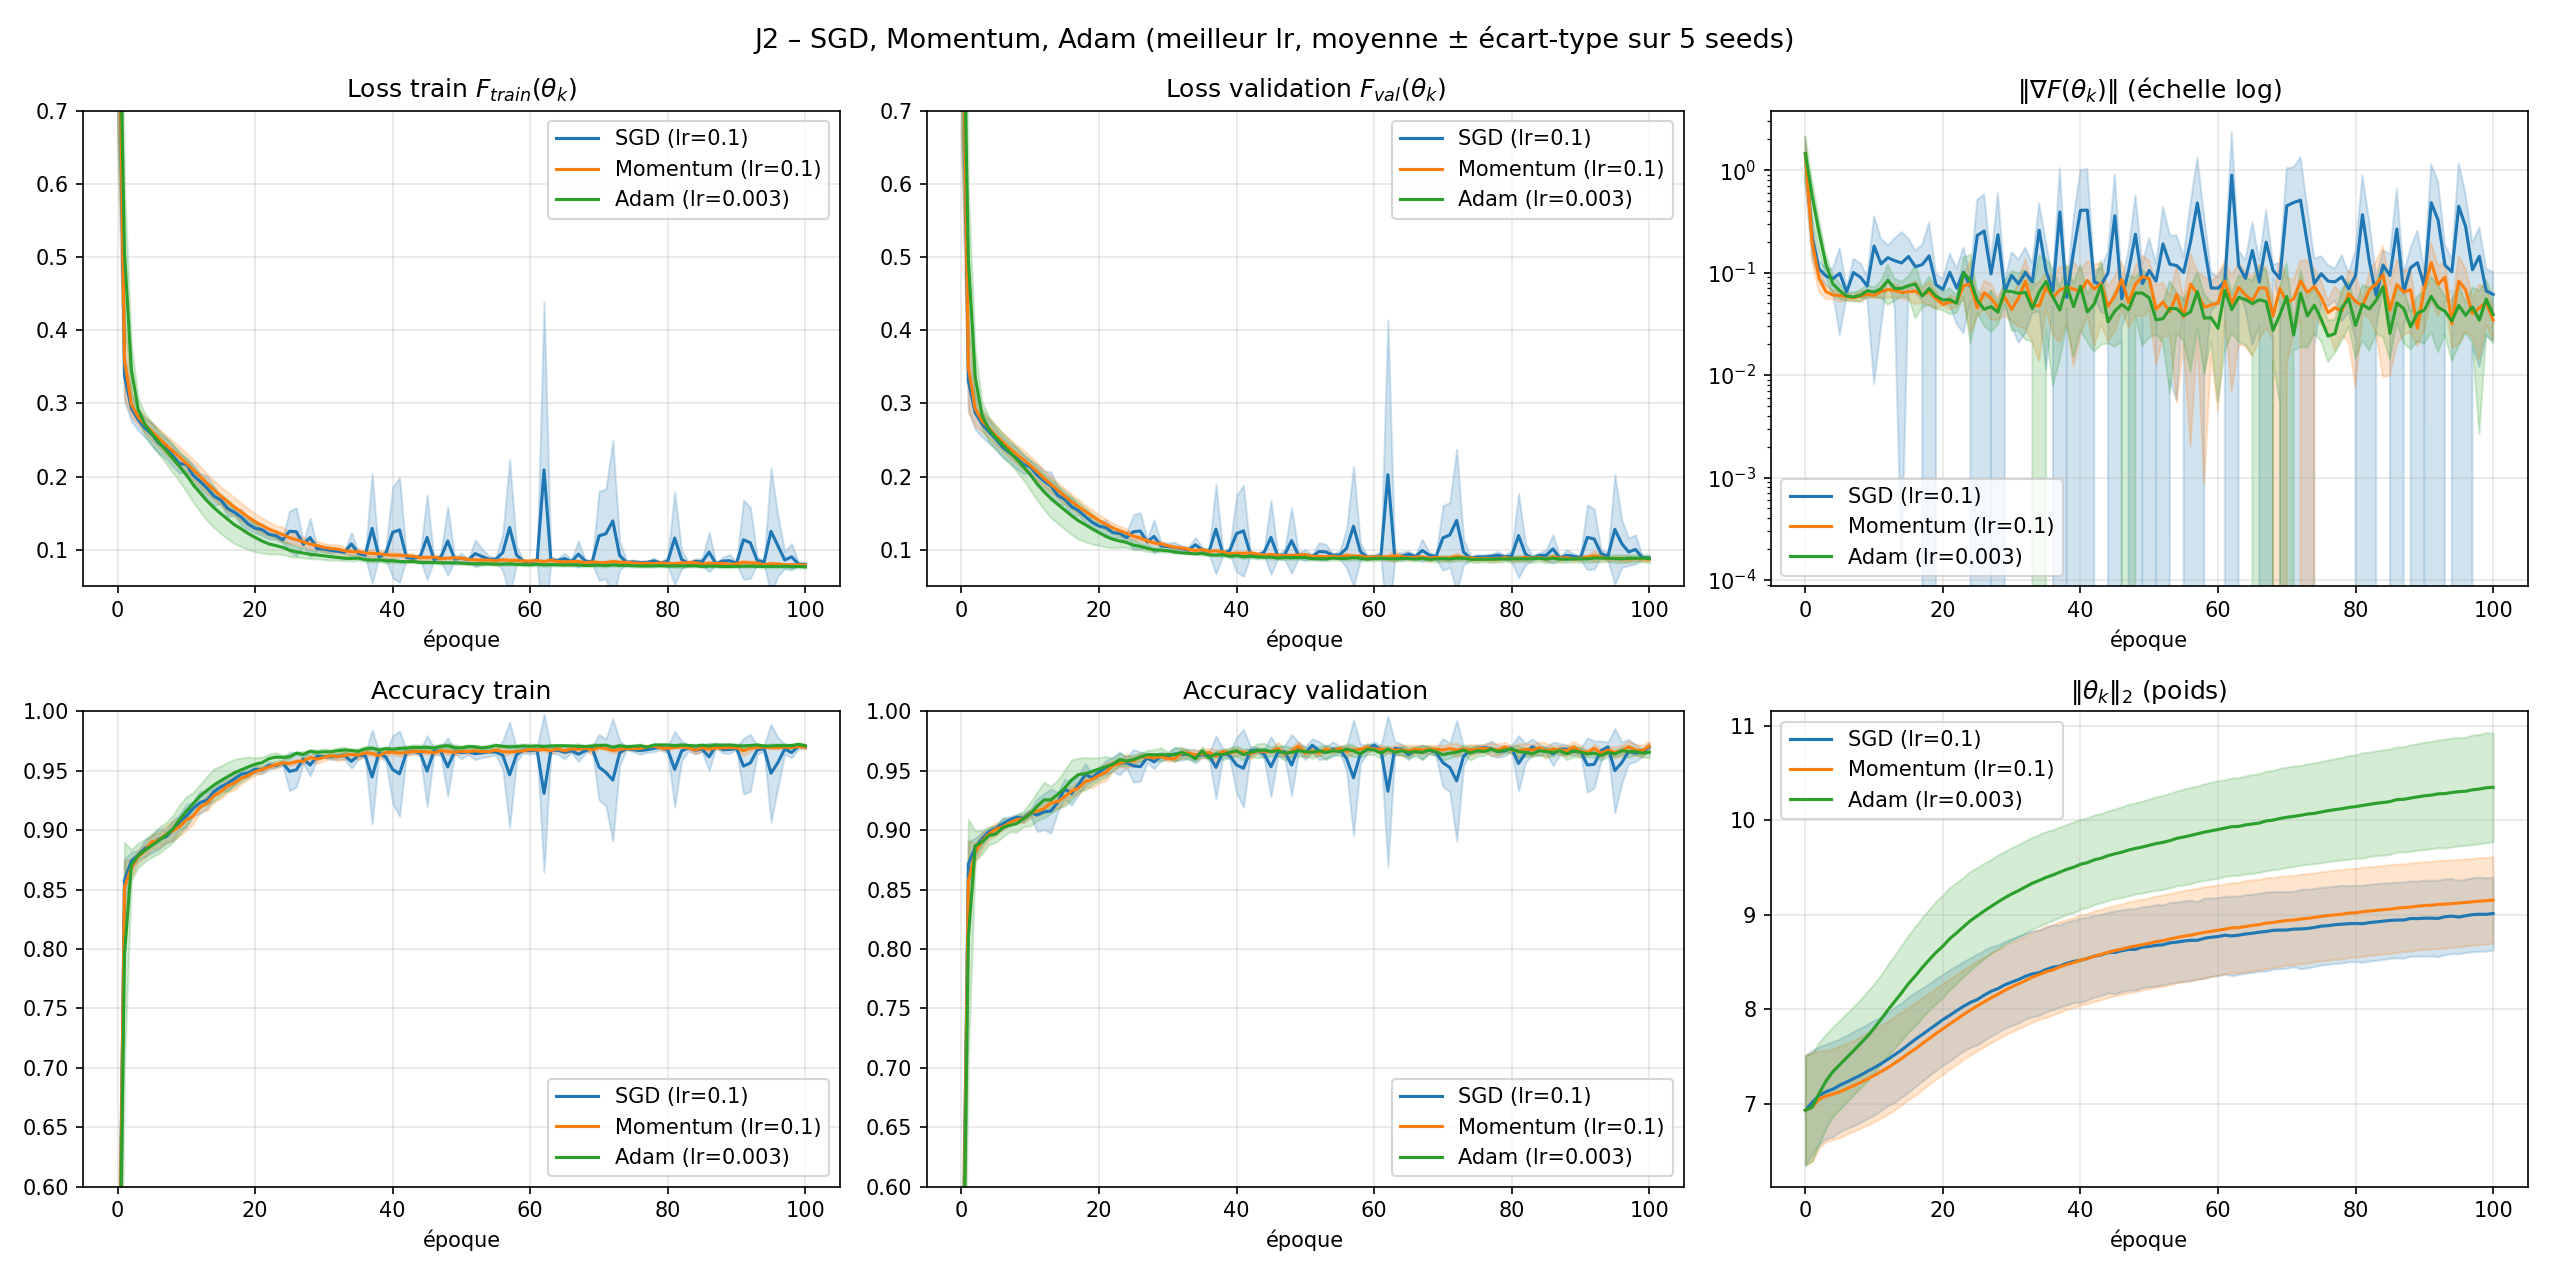

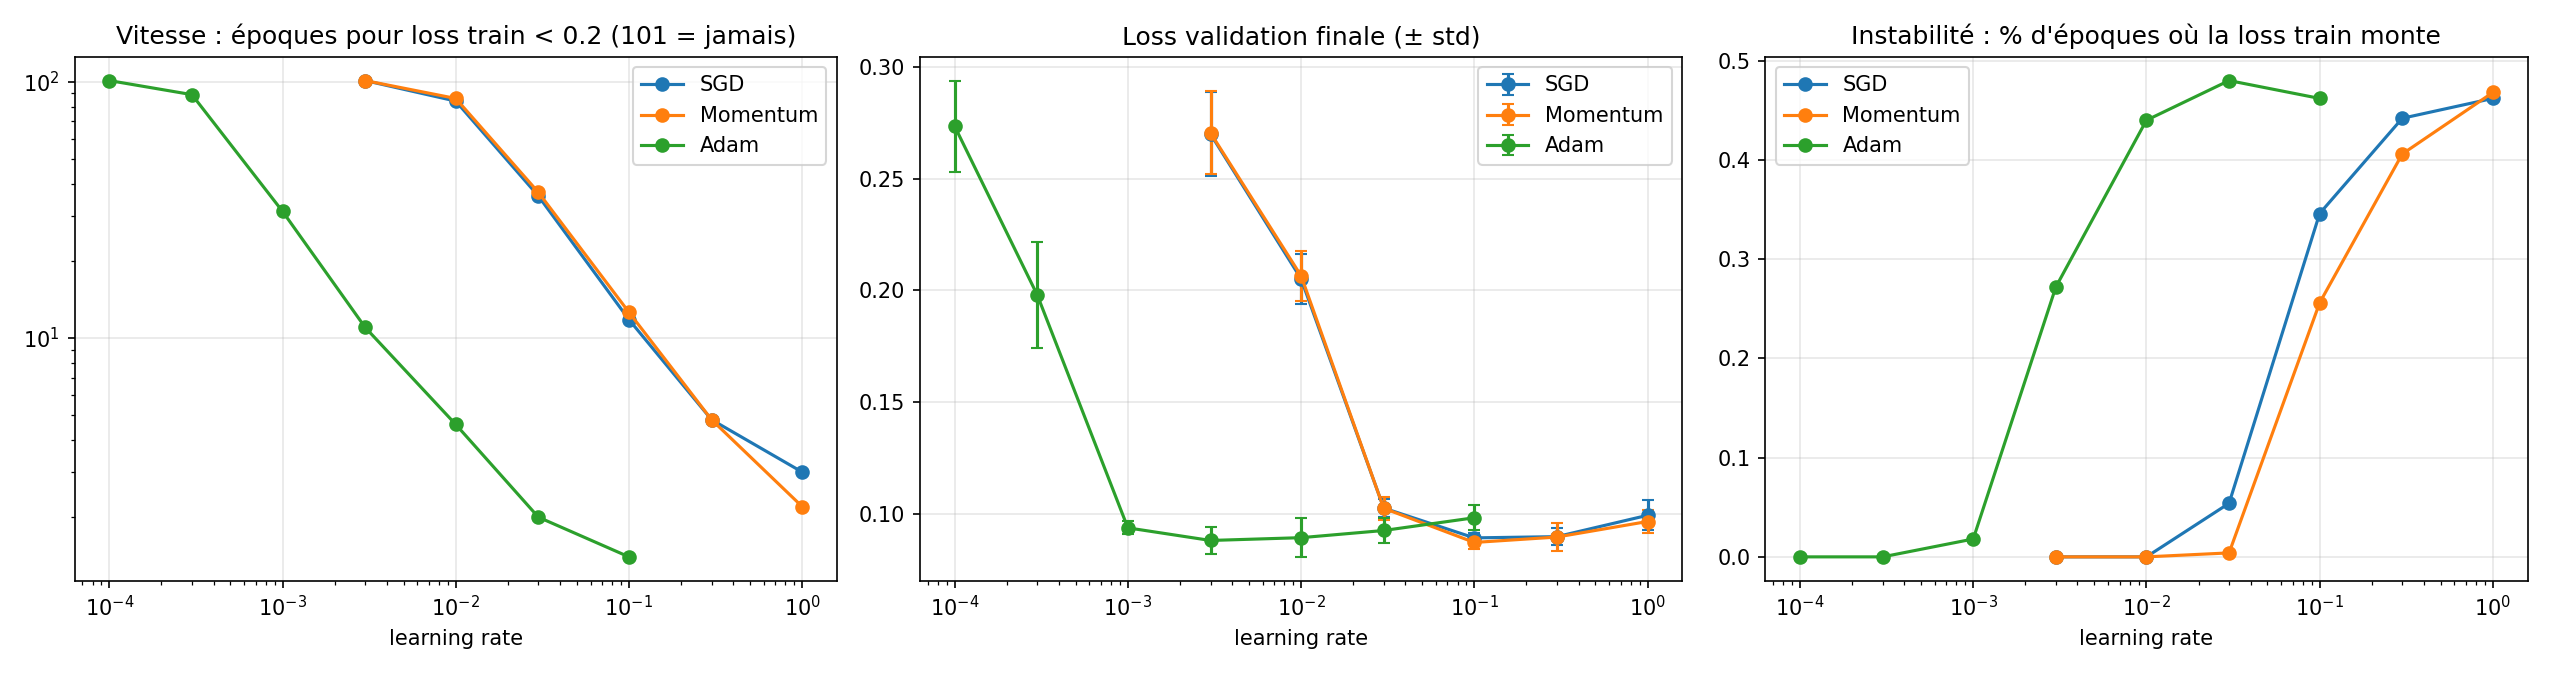

In [5]:
show_fig('j2_curves.png')
show_fig('j2_lr_sensitivity.png')

**Vitesse.** À leur meilleur learning rate, les trois optimiseurs descendent à la même vitesse : 11 à 12.6 époques pour passer sous 0.2. Les écarts apparaissent quand on augmente le learning rate. Adam passe sous 0.2 en 1.4 époque avec $\alpha = 0.1$ et en 2 époques avec $\alpha = 0.03$, Momentum en 2.2 époques avec $\alpha = 1$, et SGD en 3 époques avec $\alpha = 1$. Adam est donc le plus rapide en début d'entraînement, mais ces réglages rapides généralisent moins bien.

**Sensibilité au learning rate.** Un learning rate trop petit ne converge pas dans le budget. SGD et Momentum à $\alpha = 0.003$, et Adam à $\alpha = 10^{-4}$, restent au-dessus de 0.27 après 100 époques. Un learning rate trop grand rend l'entraînement instable (instabilité de 0.45 à 0.5) et creuse l'écart val − train, jusqu'à 0.027 pour SGD à $\alpha = 1$. Aucun entraînement n'a divergé. Les bonnes plages sont $\alpha \in [0.1, 0.3]$ pour SGD et Momentum, et $\alpha \in [0.003, 0.01]$ pour Adam.

**Validation.** Momentum ($\alpha = 0.1$) obtient la plus faible loss de validation (0.087), devant Adam (0.088) et SGD (0.089). Les écarts entre optimiseurs, de l'ordre de 0.001, sont plus petits que l'écart-type entre seeds (0.002 à 0.006) : ils ne sont pas significatifs. Adam ($\alpha = 0.003$) a servi de référence pour les parties D à F. Les trois optimiseurs étant équivalents en validation, ce choix ne modifie pas les conclusions.

### 8.2 Régularisation et généralisation (parties D1 et D2, jalon J3)

Adam, $\alpha = 0.003$, 500 époques, 5 seeds. Les valeurs sont celles de la dernière époque, sauf pour l'early stopping (époque retenue).

,hyperparamètre,époque retenue,loss train,loss val,acc val,écart val-train,||theta||
cas,,,,,,,
Sans régularisation,-,500,0.0678 ± 0.0033,0.1045 ± 0.0095,0.964 ± 0.004,0.0367 ± 0.0100,15.26 ± 2.34
L2,lambda = 0.001,500,0.0800 ± 0.0007,0.0857 ± 0.0030,0.967 ± 0.003,0.0057 ± 0.0034,6.77 ± 0.12
Dropout,taux = 0.1,500,0.0684 ± 0.0018,0.0977 ± 0.0054,0.964 ± 0.005,0.0292 ± 0.0053,18.47 ± 0.82
Early stopping,P = 20,71 ± 24,0.0793 ± 0.0024,0.0855 ± 0.0046,0.965 ± 0.006,0.0062 ± 0.0046,10.00 ± 0.68


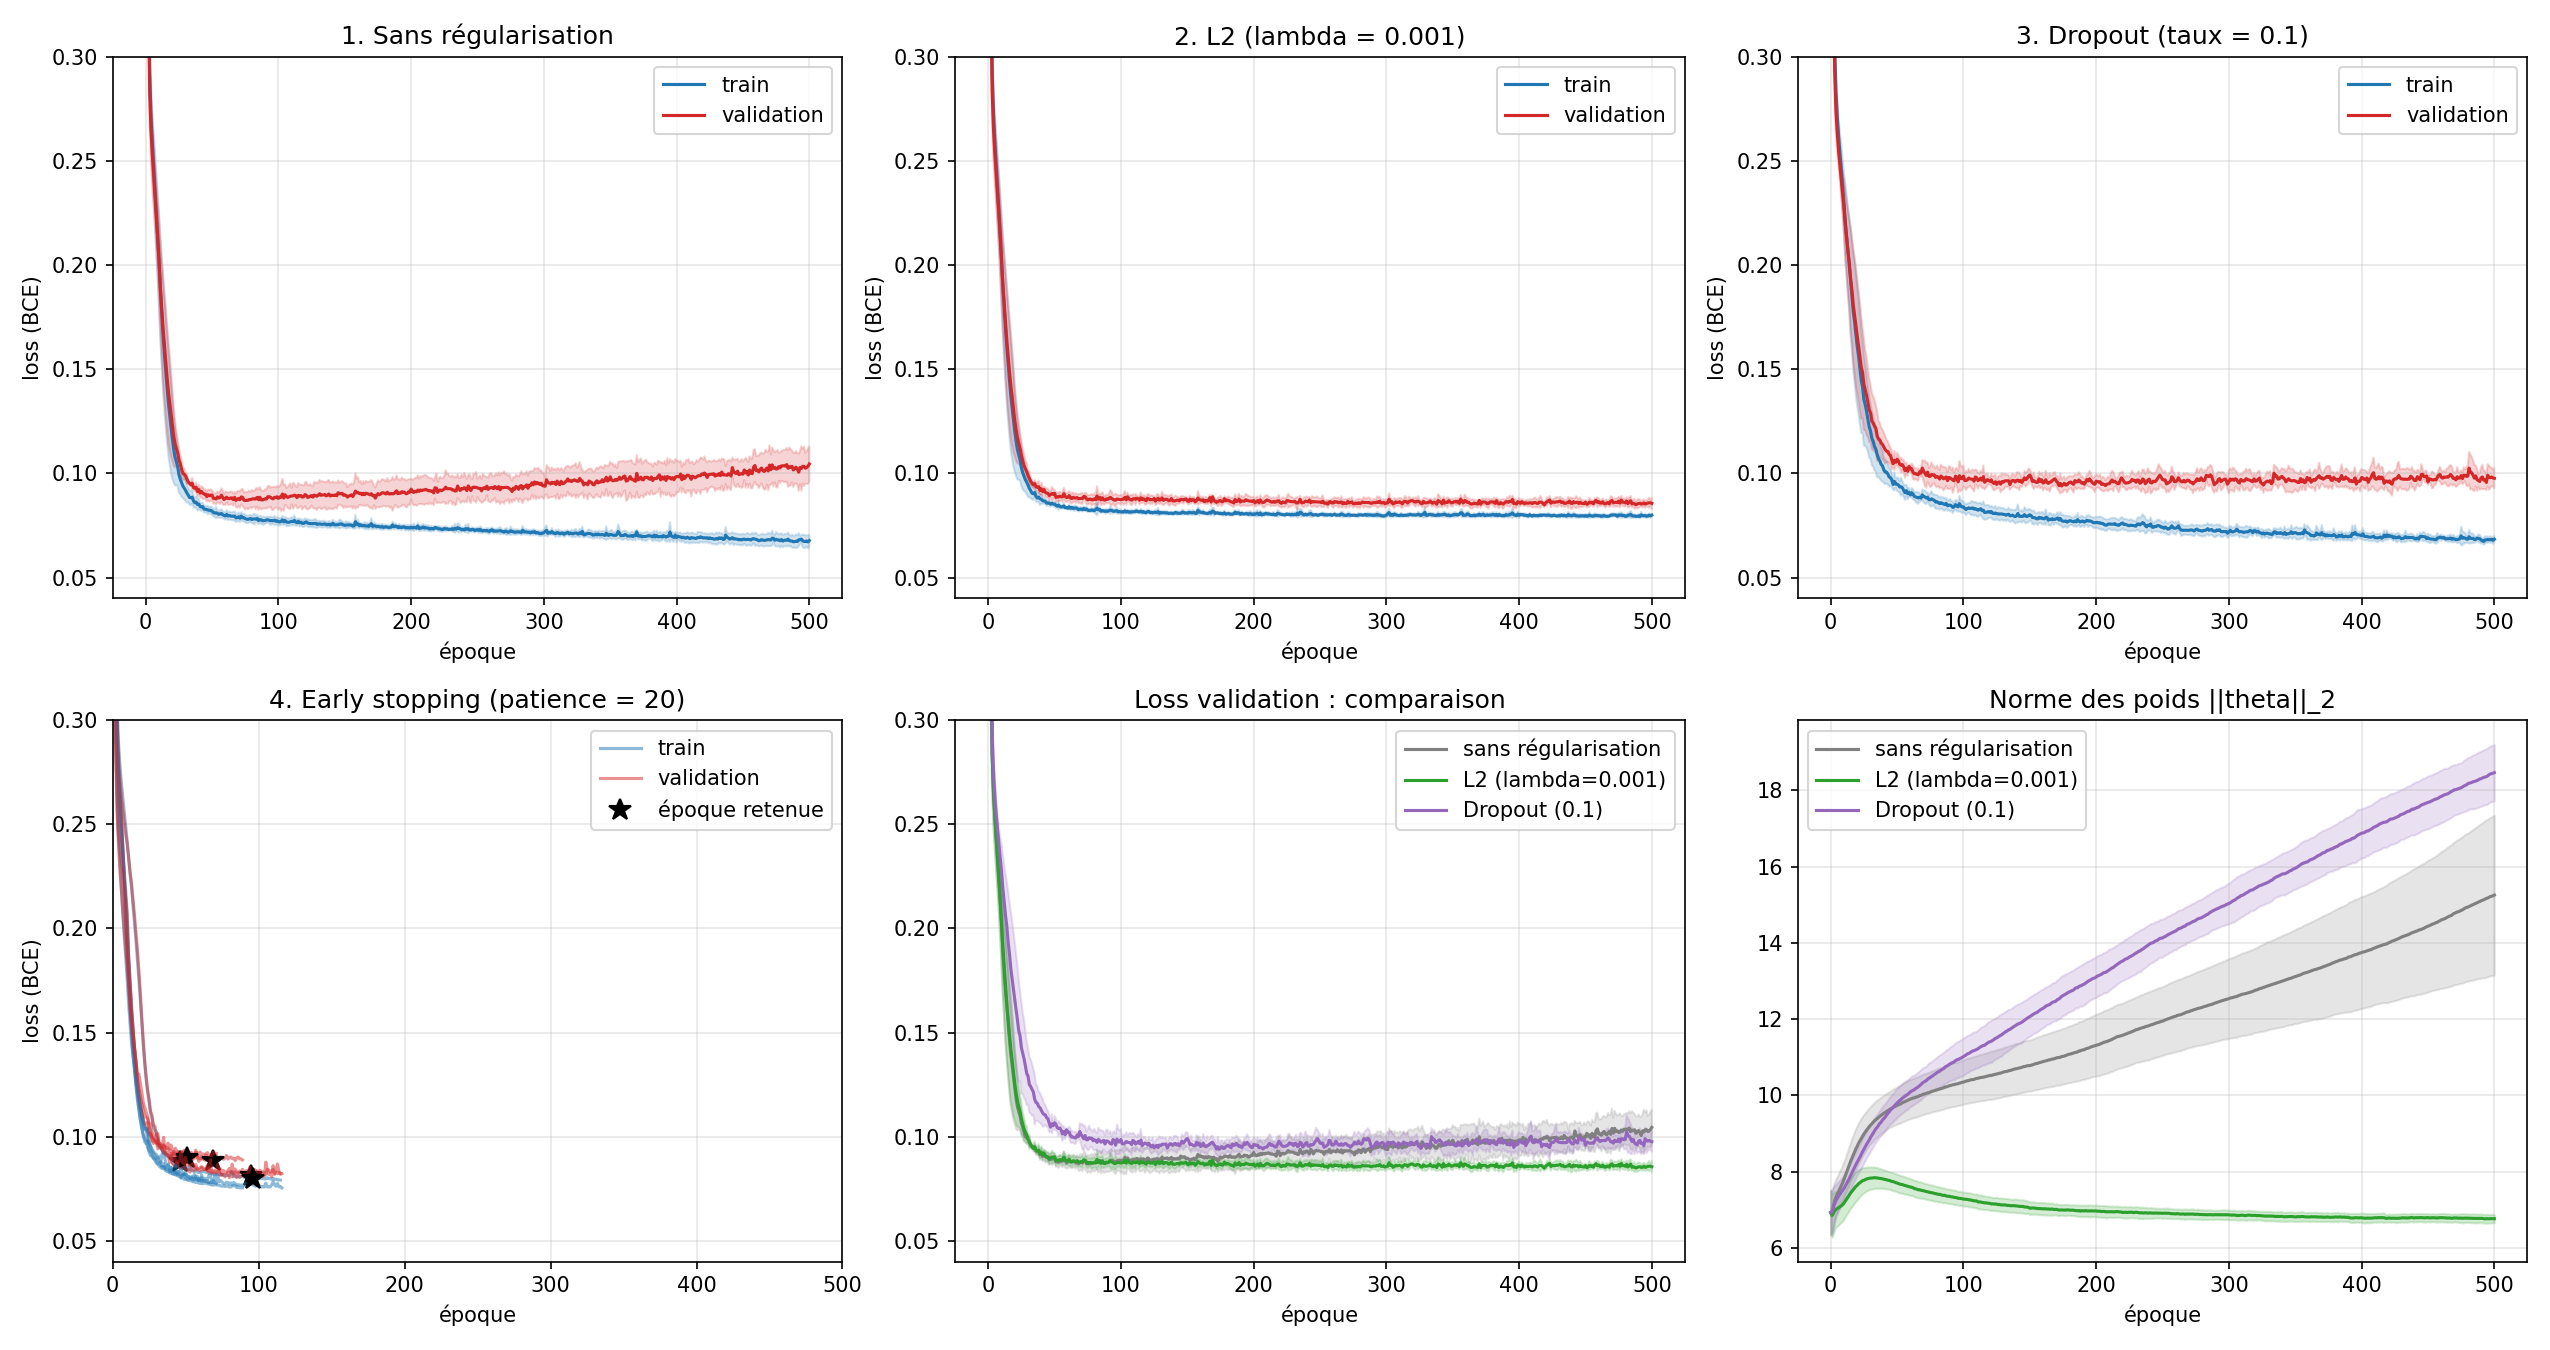

In [6]:
show_csv('d1_table.csv')
show_fig('d1_curves.png', 1000)

**Sur-apprentissage.** Sans régularisation, la loss de validation atteint son minimum vers l'époque 127 en moyenne (entre 51 et 234 selon la seed), puis remonte d'environ 0.02 pendant que la loss train continue de baisser. L'écart val − train passe de 0.008 à l'époque 50 à 0.037 à l'époque 500. L'accuracy de validation reste presque constante, autour de 0.964 : le sur-apprentissage dégrade d'abord la confiance des prédictions, mesurée par la loss, avant de toucher l'accuracy.

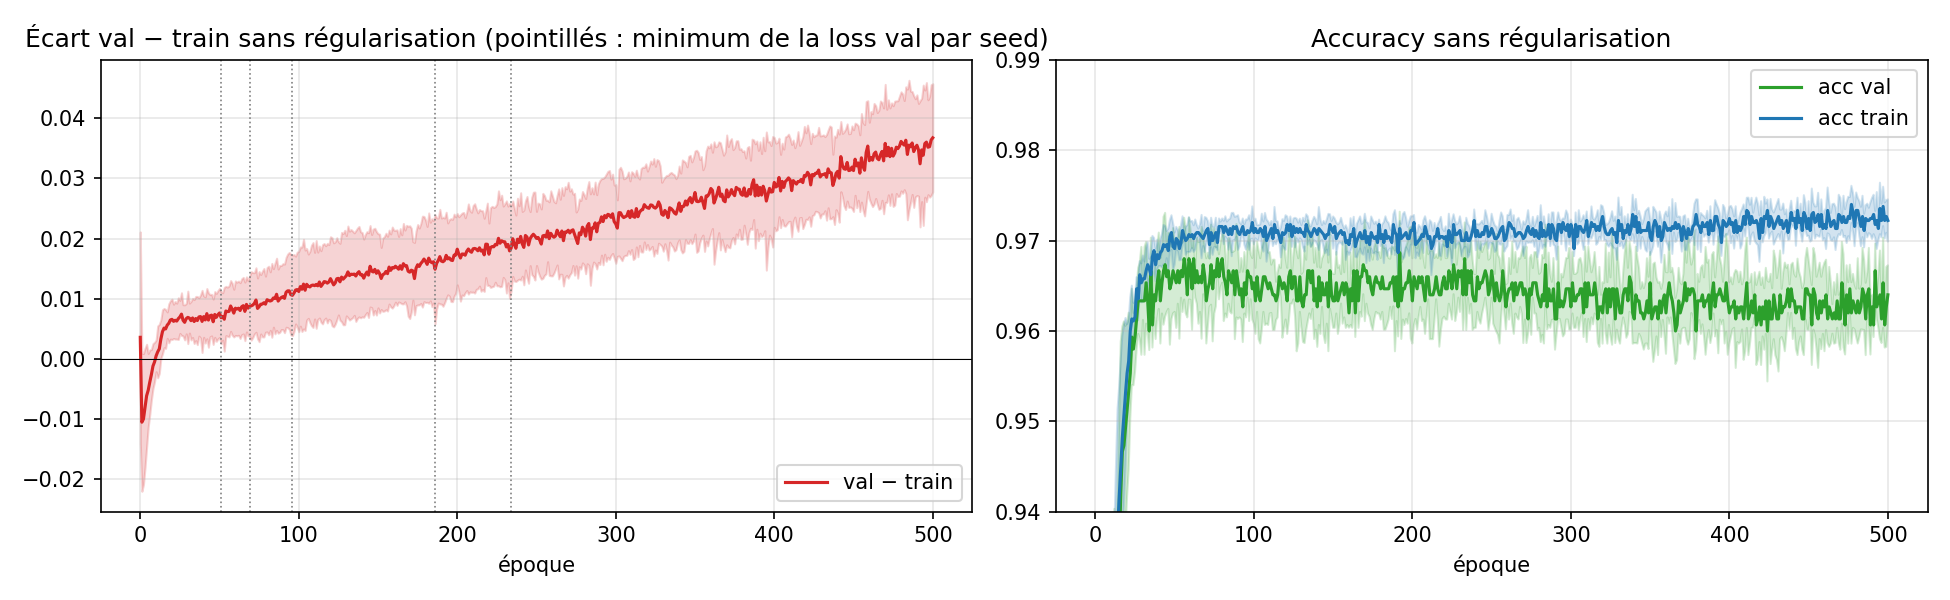

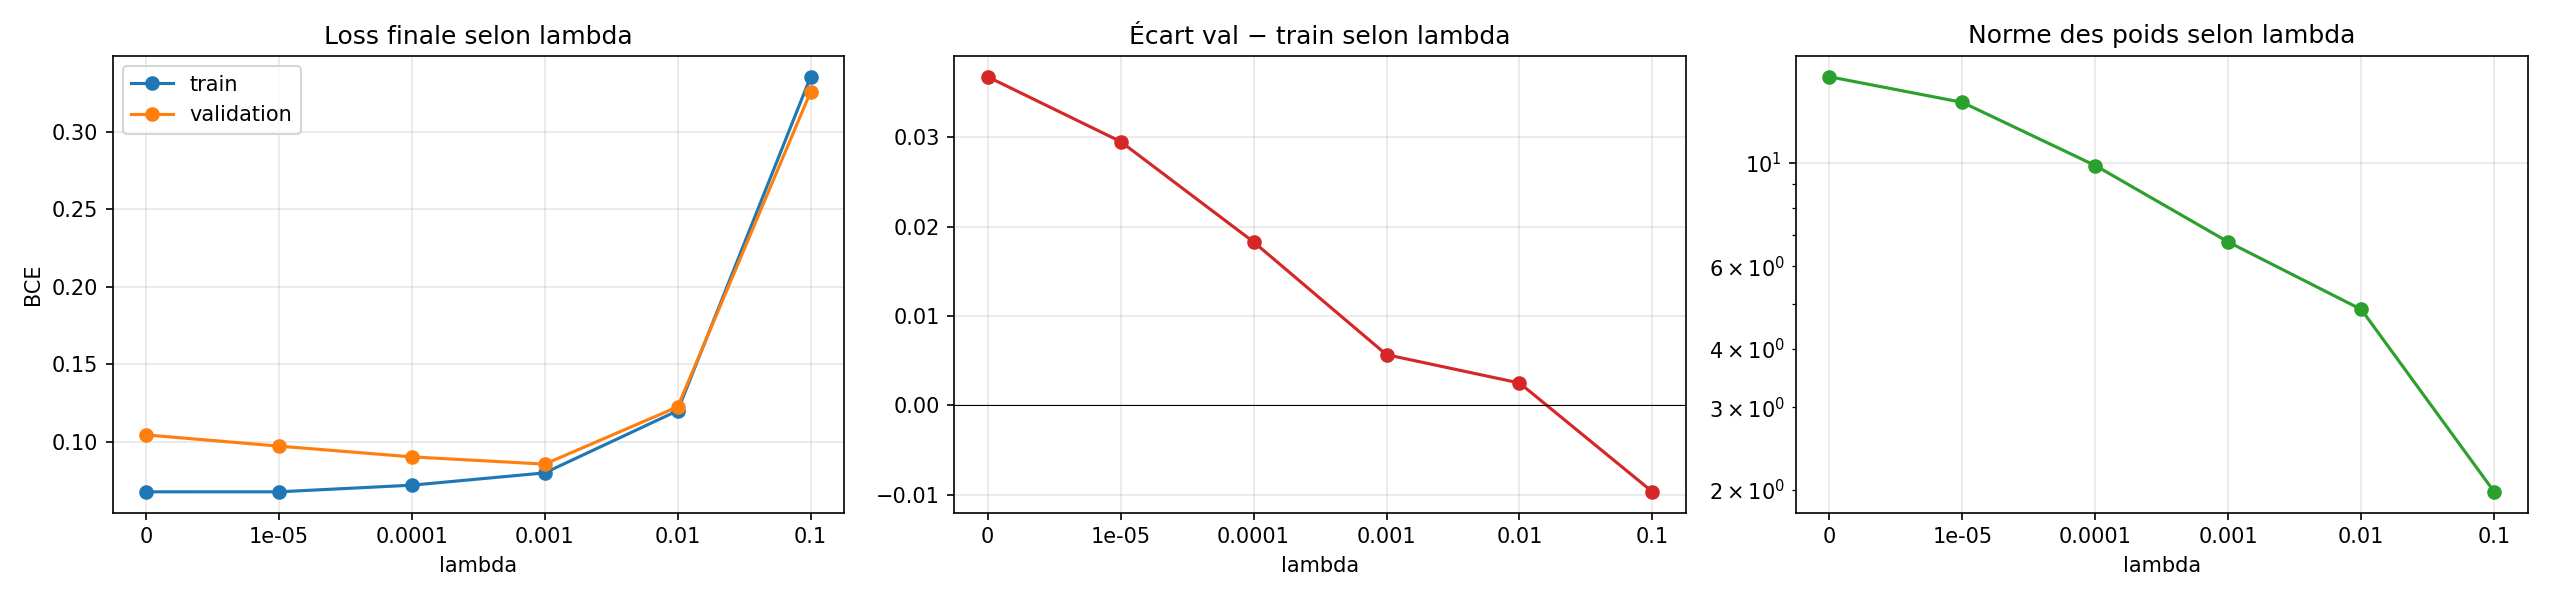

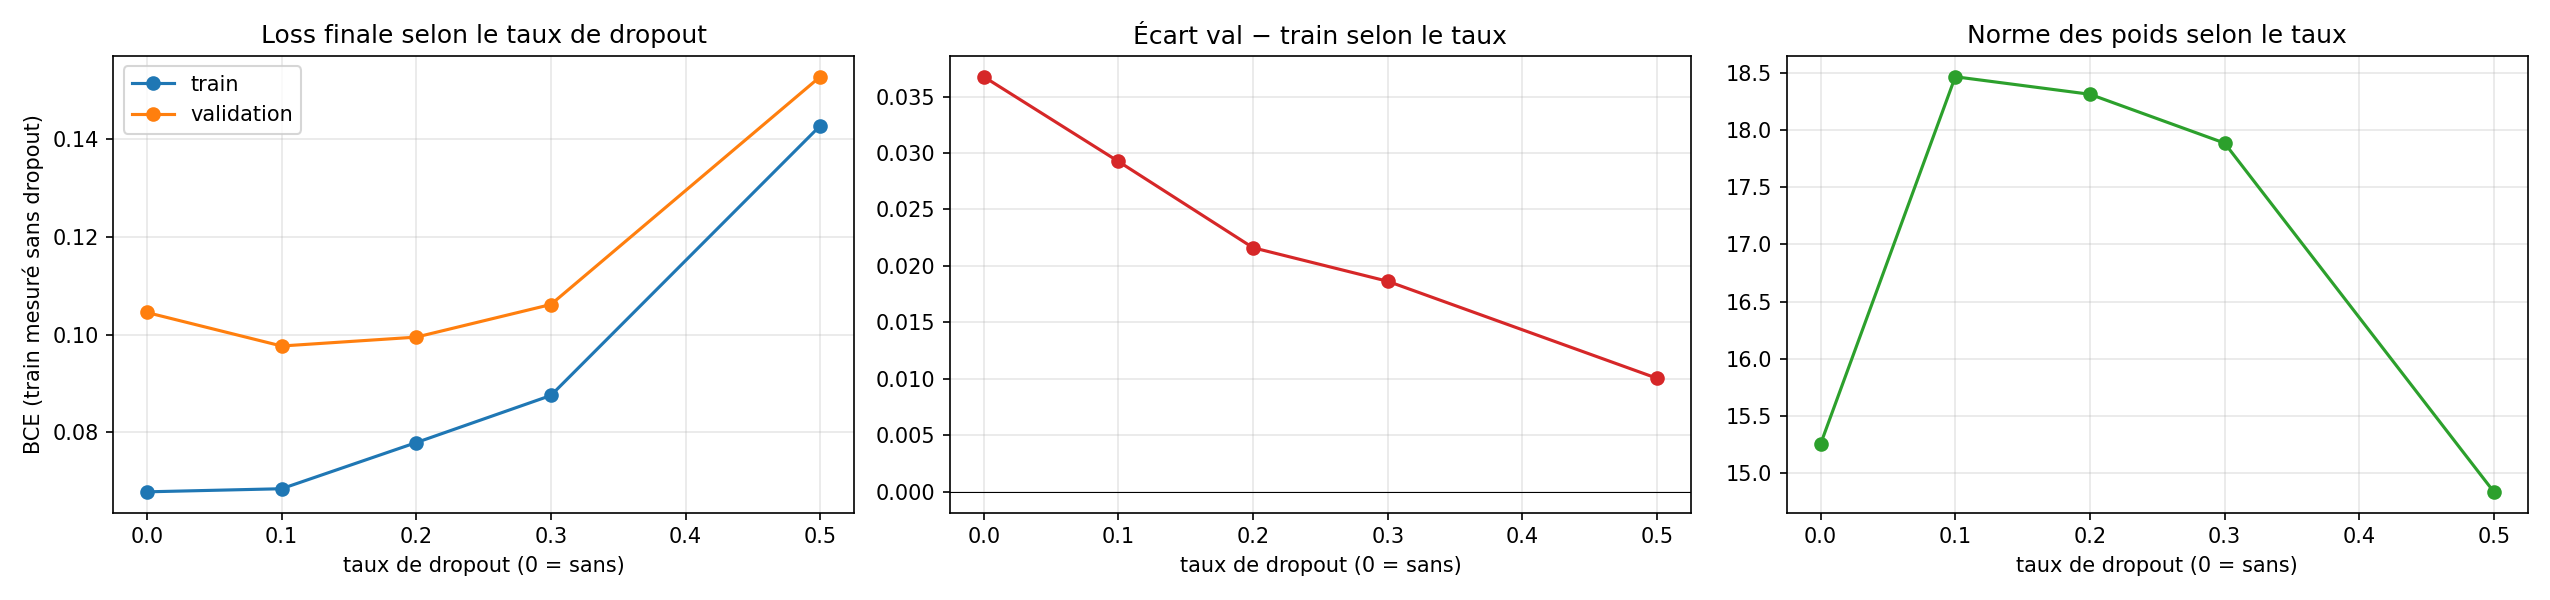

In [7]:
show_fig('d2_overfitting.png', 1000)
show_fig('d2_lambda.png', 1000)
show_fig('d2_dropout.png', 1000)

**Effet de $\lambda$.** Quand $\lambda$ augmente, la norme des poids et l'écart val − train diminuent de façon monotone. L'optimum de validation est $\lambda = 10^{-3}$ : la loss de validation passe de 0.105 à 0.086, l'écart de 0.037 à 0.006, et la norme de 15.3 à 6.8. Pour $\lambda \ge 10^{-2}$, la loss train elle-même remonte : le modèle sous-apprend.

**Effet du dropout.** Le meilleur taux de la grille est 0.1 (loss de validation 0.098). Le dropout réduit l'écart val − train (0.029), mais surtout parce que le modèle s'ajuste moins bien au train, et il ne réduit pas la norme des poids (18.5). Il agit donc autrement que $L^2$, et moins efficacement sur ce problème. À 0.5, le modèle sous-apprend.

**Early stopping.** Avec $P = 20$, le modèle retenu est celui de l'époque 71 ± 24 (entre 46 et 96 selon la seed). L'entraînement s'arrête après environ 91 époques au lieu de 500, pour une loss de validation de 0.086. Cette valeur est un minimum choisi sur la validation : elle est légèrement optimiste.

**Évaluation finale sur le test.** La règle posée avant le test retient l'early stopping, de très peu devant $L^2$.

,loss_val,loss_test,loss_test_std,acc_test,acc_test_std,test - val
cas,,,,,,
Sans régularisation,0.1045,0.0652,0.0140,0.9813,0.0087,-0.0394
L2,0.0857,0.0611,0.0019,0.9853,0.0018,-0.0246
Dropout,0.0977,0.0642,0.0059,0.9820,0.0038,-0.0334
Early stopping,0.0855,0.0600,0.0029,0.9847,0.0051,-0.0255


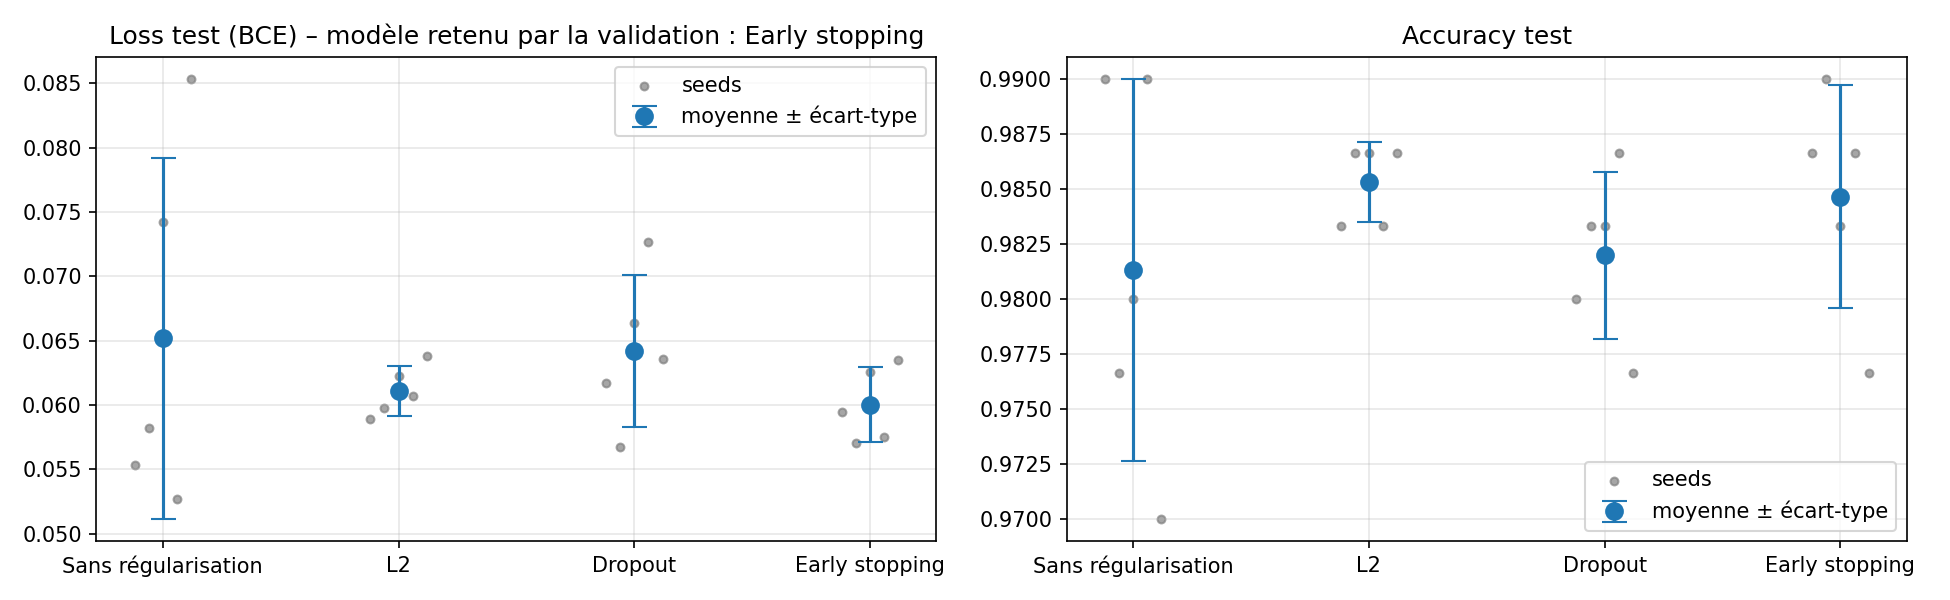

In [8]:
show_csv('d2_test_table.csv')
show_fig('d2_test.png', 1000)

Le classement sur le test est le même que sur la validation, mais les écarts ne sont pas significatifs. Les gains appariés par seed sont d'environ 0.004 à 0.005 de loss pour un écart-type d'environ 0.012, et la régularisation ne fait mieux que sur 2 ou 3 seeds sur 5. Sur 300 points de test, 0.4 point d'accuracy correspond à un seul exemple. Le bénéfice le plus net de la régularisation est la **stabilité** : l'écart-type de la loss test entre seeds passe de 0.014 sans régularisation à 0.002 avec $L^2$ et 0.003 avec l'early stopping.

### 8.3 Optimisation sous contrainte (partie E)

**Gradient projeté (E1).** La projection a été vérifiée sur ses propriétés caractéristiques : le résultat est admissible, il est inchangé s'il est déjà dans la boule, la projection est idempotente, et aucun des 5 000 points admissibles tirés au hasard n'est plus proche du point de départ. Avec SGD ($\alpha = 0.1$) et $R = 0.5\,R_0$, la norme ne dépasse jamais $R$ après projection, et la projection agit sur 66 à 81 % des pas.

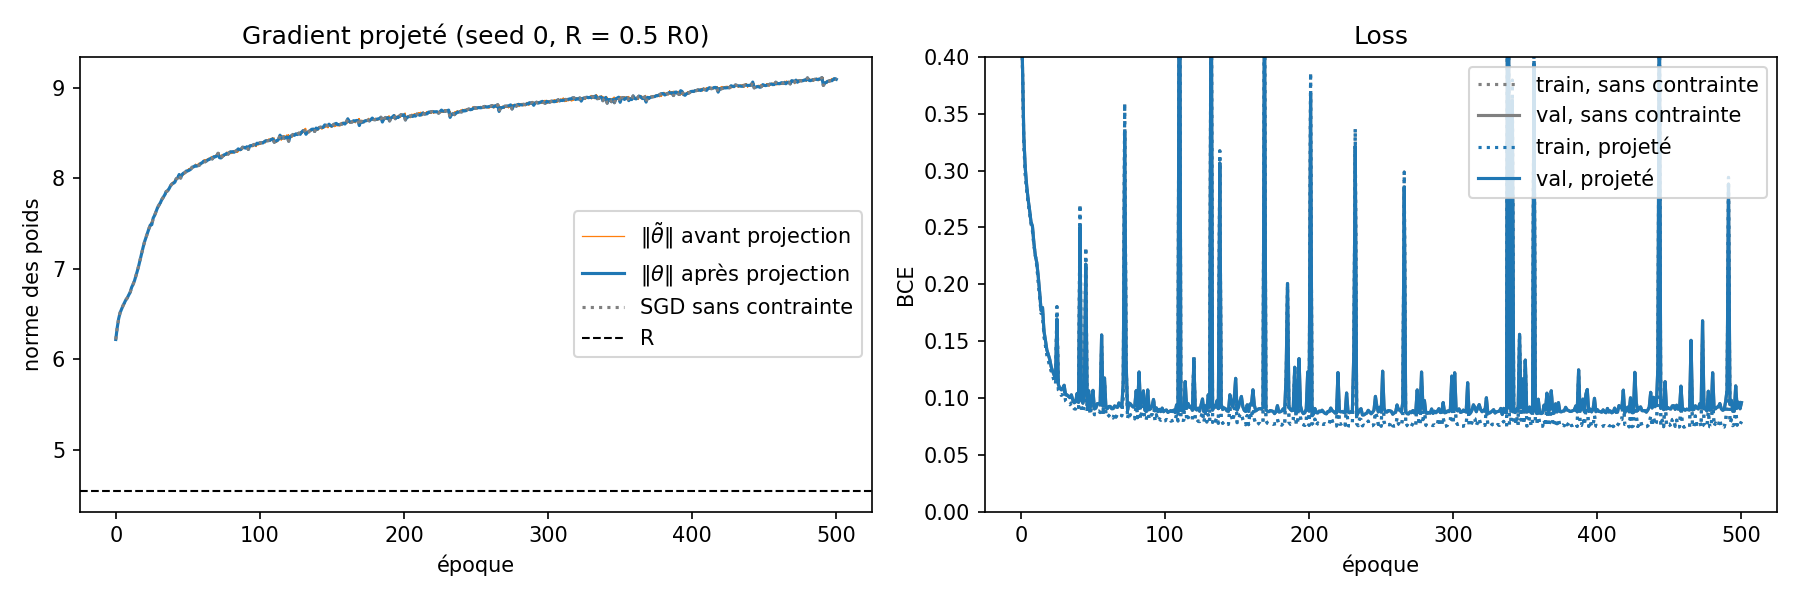

In [9]:
show_fig('E1_projected_gradient.png', 1000)

**Influence de R (E2).** $R_0$ est la norme finale de l'entraînement non contraint, calculée pour chaque seed. On teste $R \in \{0.5, 0.75, 1, 1.5, 2\}\,R_0$ avec Adam suivi d'une projection, pour garder le même optimiseur que la référence.

,R,R moyen,loss train,loss val,acc val,‖θ*‖,r_feas max,actives,pas projetés,μ estimé
0,0.5 R0,7.63,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,9.0e+00,0/5,98%,0.0001 ± 0.0001
1,0.75 R0,11.44,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,4.5e+00,0/5,62%,0.0001 ± 0.0001
2,1.0 R0,15.26,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,5/5,0%,0.0001 ± 0.0001
3,1.5 R0,22.88,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,0/5,0%,0.0001 ± 0.0001
4,2.0 R0,30.51,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,0/5,0%,0.0001 ± 0.0001
5,sans contrainte,∞,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,–,–,–,–


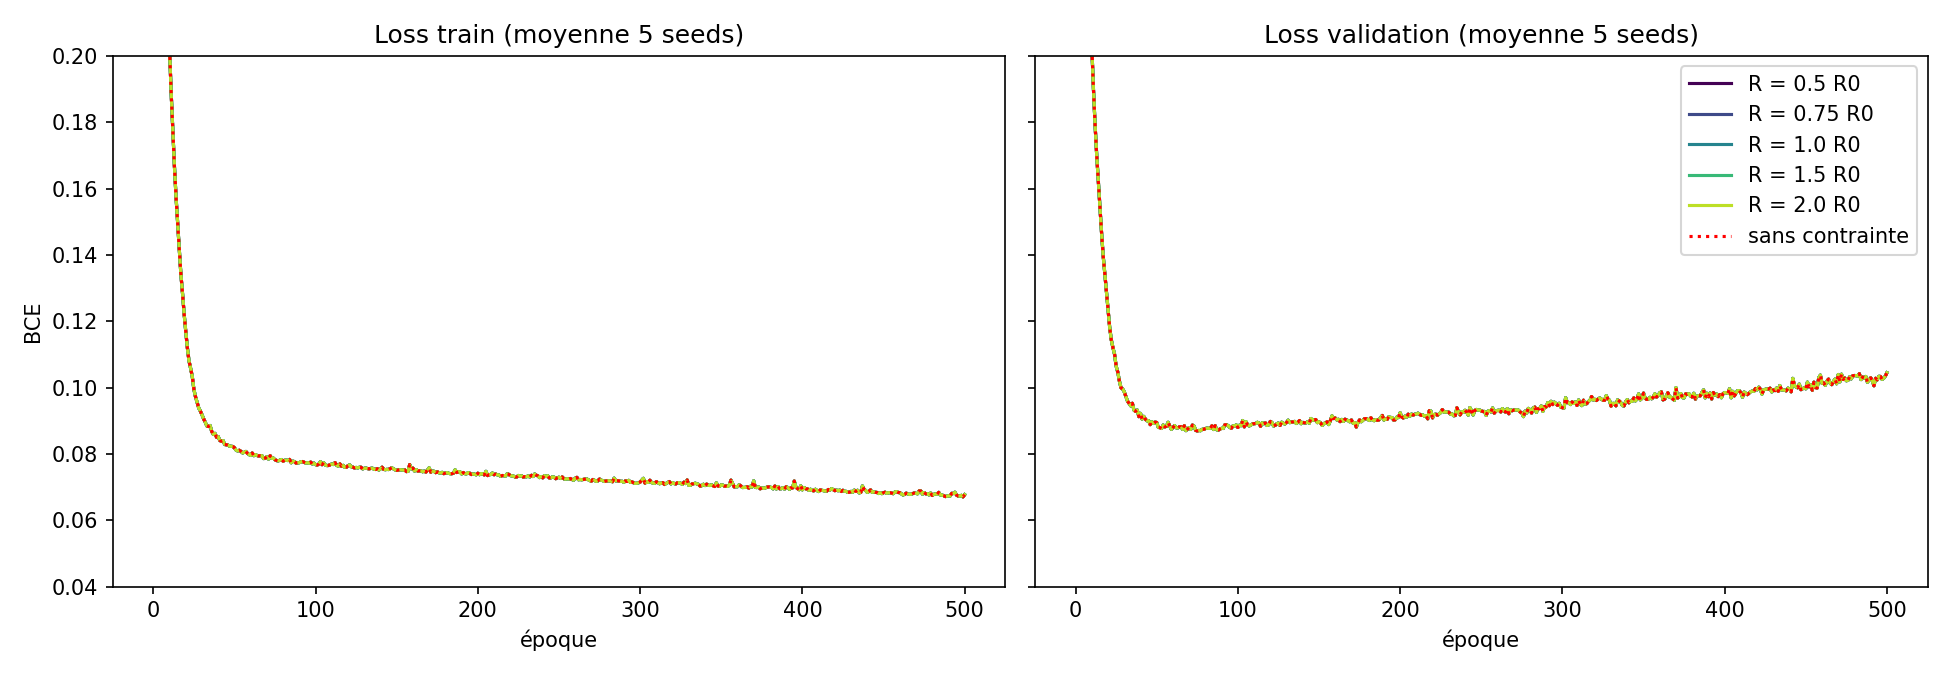

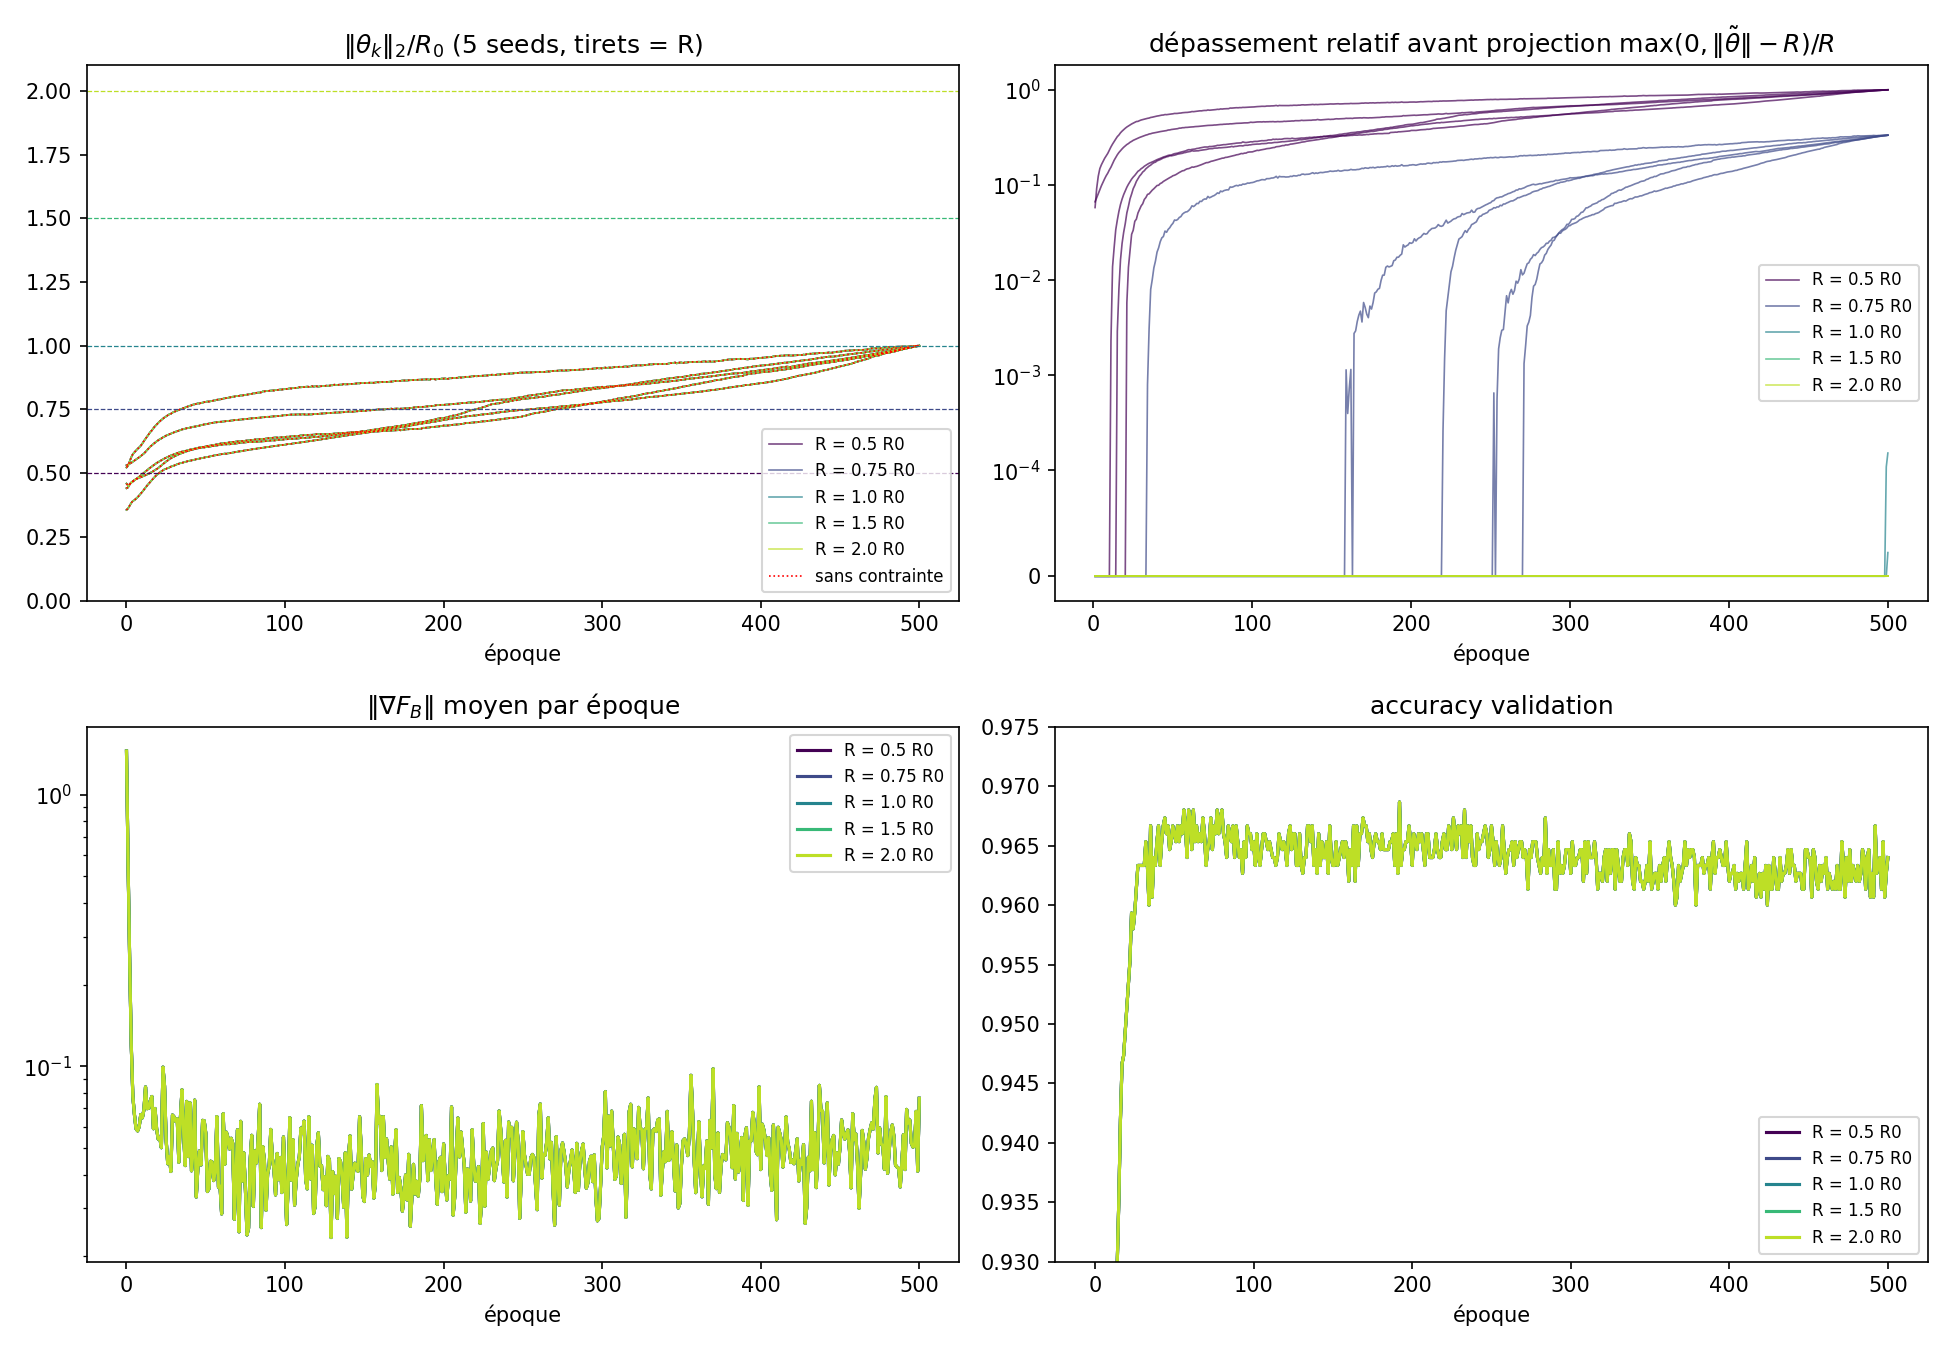

In [10]:
show_csv('E2_table.csv', index_col=None)
show_fig('E2_loss_curves.png', 1000)
show_fig('E2_constraint_curves.png', 1000)

Diminuer $R$ fait monter la loss train : 0.066 pour $R \ge R_0$, 0.072 à $0.75\,R_0$ et 0.094 à $0.5\,R_0$. La loss de validation finale est meilleure avec une contrainte modérée : 0.090 à $0.75\,R_0$ contre 0.104 sans contrainte. À $0.75\,R_0$, la contrainte ne s'active que vers l'époque 250. Avant, la trajectoire est celle de la référence. Après, la norme est bloquée et la loss de validation reste plate au lieu de remonter. La contrainte supprime donc la phase de sur-apprentissage, un peu comme un early stopping portant sur la norme. À $0.5\,R_0$, elle est trop serrée et le modèle sous-apprend.

Après projection, le résidu $r_{feas}(k)$ reste inférieur à $4 \cdot 10^{-15}$ à toutes les époques : c'est l'erreur d'arrondi, et la contrainte est respectée par construction. Avant projection, chaque pas sort légèrement de la boule (de l'ordre de $10^{-3} R$ à $0.5\,R_0$), et la projection ramène sur le bord.

### 8.4 Pénalisation ou contrainte explicite (partie F, jalon J4)

**Construction des couples.** Pour chaque $\lambda \in \{10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}\}$ et chaque seed, on entraîne le modèle pénalisé, on prend sa norme finale comme $R$, puis on entraîne le modèle contraint avec la même seed et le même optimiseur. Les deux modèles d'un couple ont ainsi la même initialisation, les mêmes mini-batchs et la même norme finale. La comparaison principale utilise SGD ($\alpha = 0.1$), avec lequel la version contrainte est exactement le gradient projeté du sujet.

R moyen       loss train         loss val  \
optimiseur λ       méthode                                                 
SGD        0.00001 pénalité       9.97  0.0781 ± 0.0066  0.0953 ± 0.0032   
                   contrainte     9.97  0.0781 ± 0.0067  0.0958 ± 0.0028   
           0.00010 pénalité       9.44  0.0799 ± 0.0081  0.0960 ± 0.0067   
                   contrainte     9.44  0.0781 ± 0.0067  0.0958 ± 0.0028   
           0.00100 pénalité       6.92  0.0835 ± 0.0030  0.0897 ± 0.0054   
                   contrainte     6.92  0.0781 ± 0.0067  0.0958 ± 0.0028   
           0.01000 pénalité       4.86  0.1258 ± 0.0068  0.1271 ± 0.0062   
                   contrainte     4.86  0.0781 ± 0.0067  0.0958 ± 0.0028   
Adam       0.00001 pénalité      13.45  0.0678 ± 0.0028  0.0973 ± 0.0076   
                   contrainte    13.45  0.0678 ± 0.0033  0.1045 ± 0.0095   
           0.00010 pénalité       9.86  0.0721 ± 0.0014  0.0903 ± 0.0079   
                   contrainte     9.86  0.0678 ± 0.0033  0.1045 ± 0.0095   
           0.00100 pénalité       6.77  0.0800 ± 0.0007  0.0857 ± 0.0030   
                   contrainte     6.77  0.0678 ± 0.0033  0.1045 ± 0.0095   
           0.01000 pénalité       4.86  0.1201 ± 0.0012  0.1226 ± 0.0003   
                   contrainte     4.86  0.0678 ± 0.0033  0.1045 ± 0.0095   

                                     acc val           ‖θ‖ contrainte active  \
optimiseur λ       méthode                                                     
SGD        0.00001 pénalité    0.965 ± 0.004   9.97 ± 0.53                 –   
                   contrainte  0.965 ± 0.004  10.03 ± 0.54               0/5   
           0.00010 pénalité    0.965 ± 0.007   9.44 ± 0.45                 –   
                   contrainte  0.965 ± 0.004  10.03 ± 0.54               0/5   
           0.00100 pénalité    0.967 ± 0.002   6.92 ± 0.21                 –   
                   contrainte  0.965 ± 0.004  10.03 ± 0.54               0/5   
           0.01000 pénalité    0.955 ± 0.004   4.86 ± 0.02                 –   
                   contrainte  0.965 ± 0.004  10.03 ± 0.54               0/5   
Adam       0.00001 pénalité    0.965 ± 0.004  13.45 ± 1.45                 –   
                   contrainte  0.964 ± 0.004  15.26 ± 2.34               0/5   
           0.00010 pénalité    0.966 ± 0.004   9.86 ± 0.49                 –   
                   contrainte  0.964 ± 0.004  15.26 ± 2.34               0/5   
           0.00100 pénalité    0.967 ± 0.003   6.77 ± 0.12                 –   
                   contrainte  0.964 ± 0.004  15.26 ± 2.34               0/5   
           0.01000 pénalité    0.957 ± 0.005   4.86 ± 0.01                 –   
                   contrainte  0.964 ± 0.004  15.26 ± 2.34               0/5   

                              pas projetés           μ estimé   cos  
optimiseur λ       méthode                                           
SGD        0.00001 pénalité              –  0.00036 ± 0.00049 -0.01  
                   contrainte           6%  0.00033 ± 0.00051 -0.01  
           0.00010 pénalité              –  0.00051 ± 0.00064 -0.00  
                   contrainte          52%  0.00033 ± 0.00051 -0.01  
           0.00100 pénalité              –  0.00141 ± 0.00098  0.11  
                   contrainte          99%  0.00033 ± 0.00051 -0.01  
           0.01000 pénalité              –  0.01333 ± 0.00617  0.49  
                   contrainte         100%  0.00033 ± 0.00051 -0.01  
Adam       0.00001 pénalité              –  0.00017 ± 0.00016  0.03  
                   contrainte          25%  0.00014 ± 0.00013  0.02  
           0.00010 pénalité              –  0.00035 ± 0.00033  0.07  
                   contrainte          88%  0.00014 ± 0.00013  0.02  
           0.00100 pénalité              –  0.00123 ± 0.00082  0.19  
                   contrainte         100%  0.00014 ± 0.00013  0.02  
           0.01000 pénalité              –  0.01066 ± 0.00128  0.73  
                   contrainte  

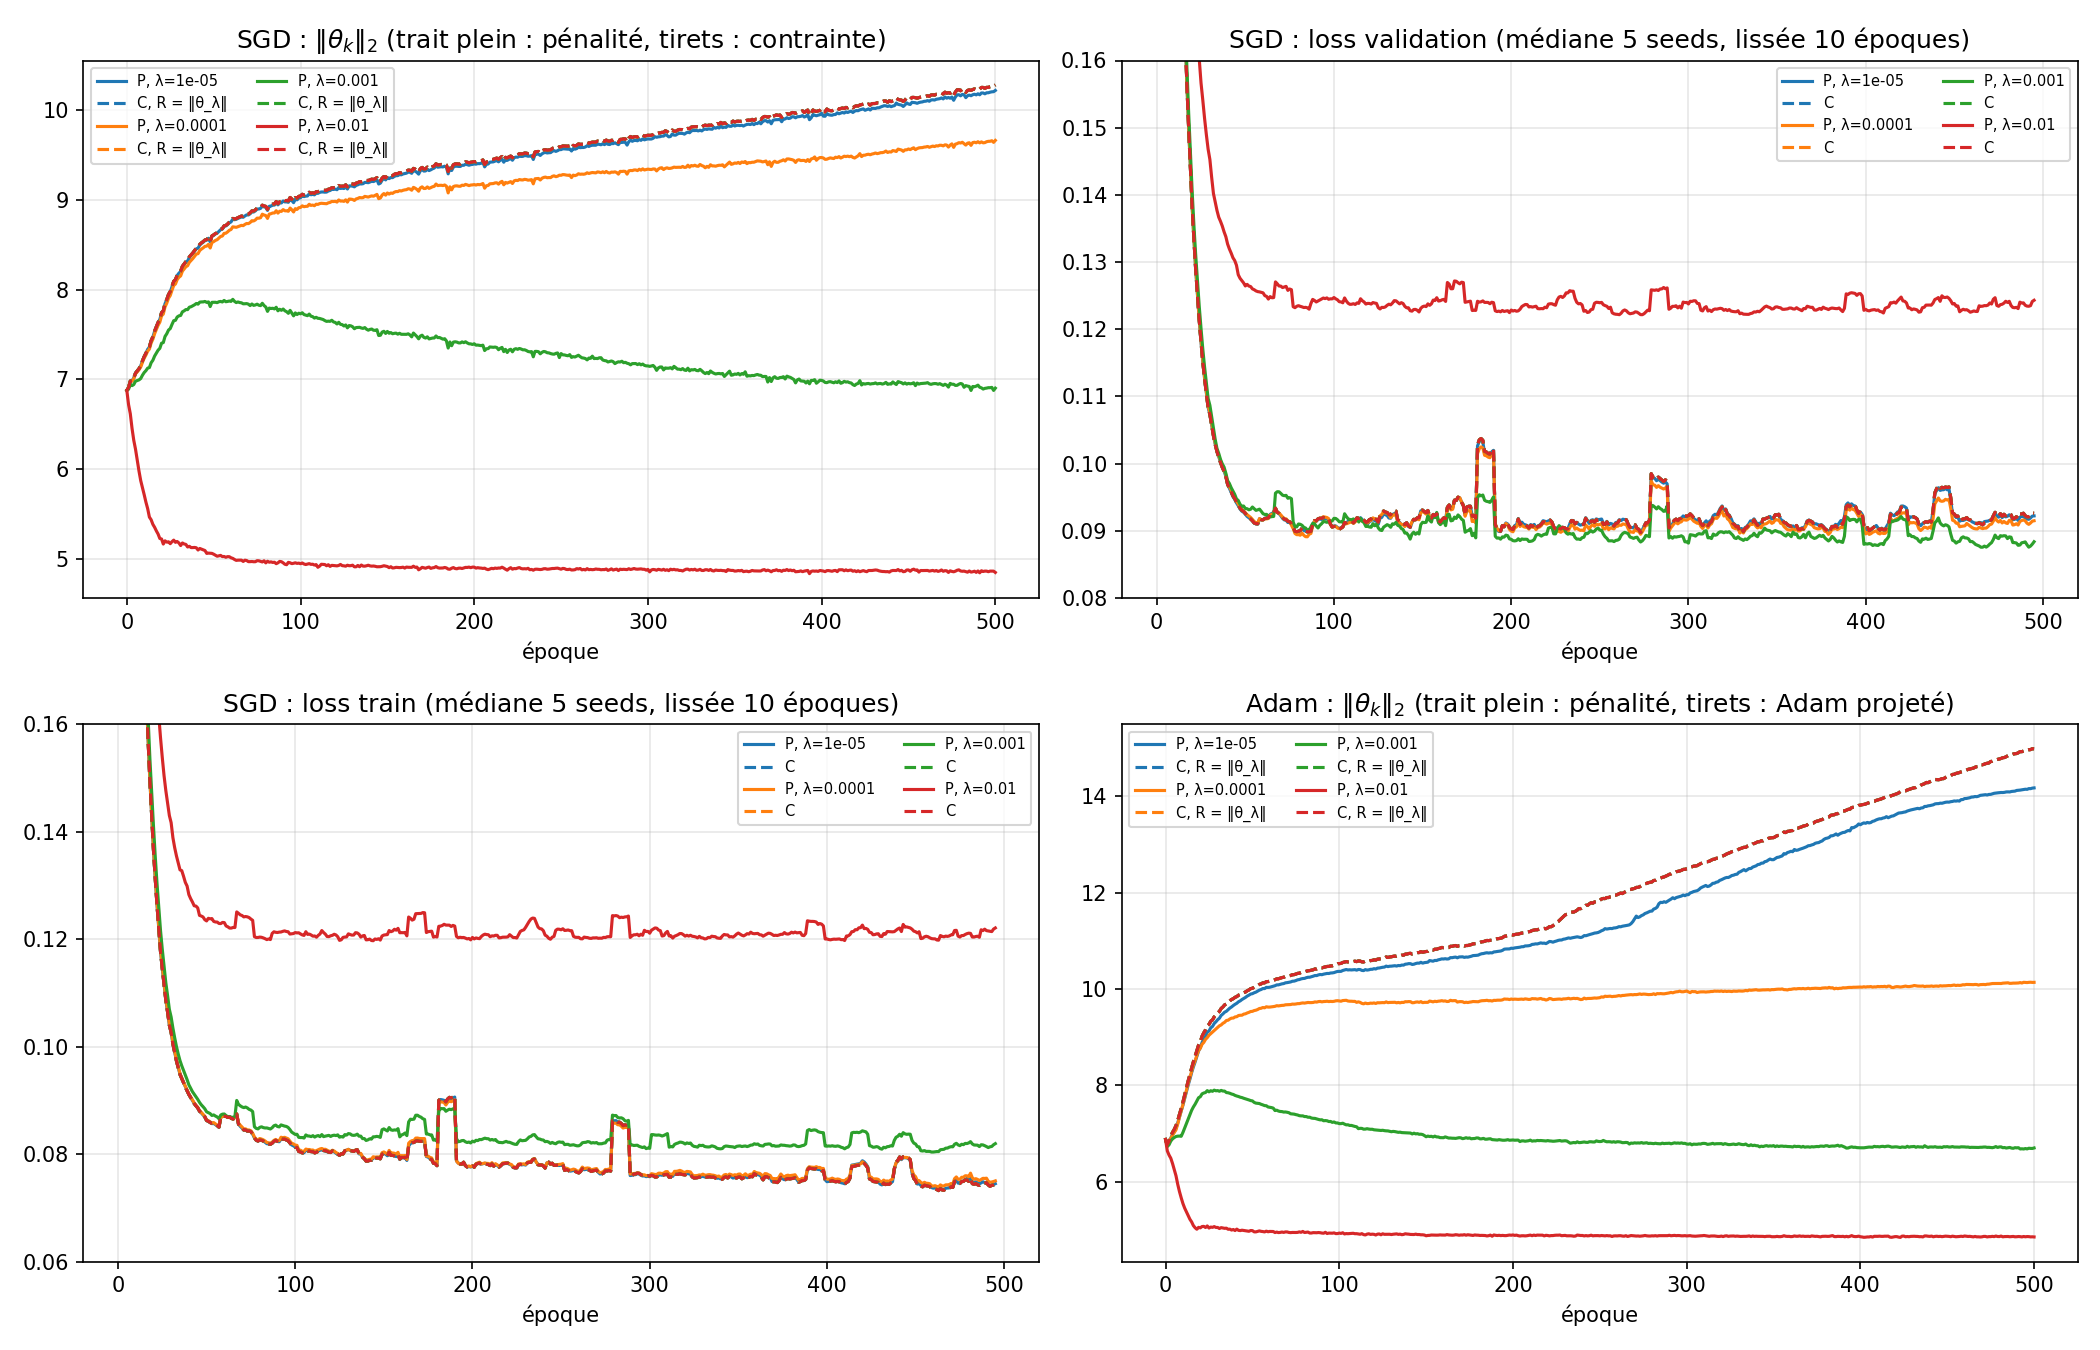

dispersion entre seeds (loss val finale)  \
optimiseur λ       méthode                                                
SGD        0.00001 pénalité                                     0.00318   
                   contrainte                                   0.00276   
           0.00010 pénalité                                     0.00670   
                   contrainte                                   0.00276   
           0.00100 pénalité                                     0.00542   
                   contrainte                                   0.00276   
           0.01000 pénalité                                     0.00623   
                   contrainte                                   0.00276   
Adam       0.00001 pénalité                                     0.00763   
                   contrainte                                   0.00955   
           0.00010 pénalité                                     0.00795   
                   contrainte                                   0.00955   
           0.00100 pénalité                                     0.00304   
                   contrainte                                   0.00955   
           0.01000 pénalité                                     0.00029   
                   contrainte                                   0.00955   

                               oscillation (100 dernières époques)  \
optimiseur λ       méthode                                           
SGD        0.00001 pénalité                                0.01070   
                   contrainte                              0.01072   
           0.00010 pénalité                                0.01061   
                   contrainte                              0.01072   
           0.00100 pénalité                                0.00886   
                   contrainte                              0.01072   
           0.01000 pénalité                                0.00730   
                   contrainte                              0.01072   
Adam       0.00001 pénalité                                0.00148   
                   contrainte                              0.00206   
           0.00010 pénalité                                0.00136   
                   contrainte                              0.00206   
           0.00100 pénalité                                0.00102   
                   contrainte                              0.00206   
           0.01000 pénalité                                0.00077   
                   contrainte                              0.00206   

                               dérive val (époque 400 → 500)  \
optimiseur λ       méthode                                     
SGD        0.00001 pénalité                          0.00235   
                   contrainte                        0.00294   
           0.00010 pénalité                          0.00370   
                   contrainte                        0.00294   
           0.00100 pénalité                         -0.00304   
                   contrainte                        0.00294   
           0.01000 pénalité                          0.00321   
                   contrainte                        0.00294   
Adam       0.00001 pénalité                          0.00370   
                   contrainte                        0.00596   
           0.00010 pénalité                          0.00071   
                   contrainte                        0.00596   
           0.00100 pénalité                         -0.00050   
                   contrainte                        0.00596   
           0.01000 pénalité                          0.00043   
                   contrainte                        0.00596   

                               pics de loss val (> 1.5 × médiane, 100 dernières)  
optimiseur λ       méthode                                                        
SGD        0.00001 pénalité                                                  2.2  
                 

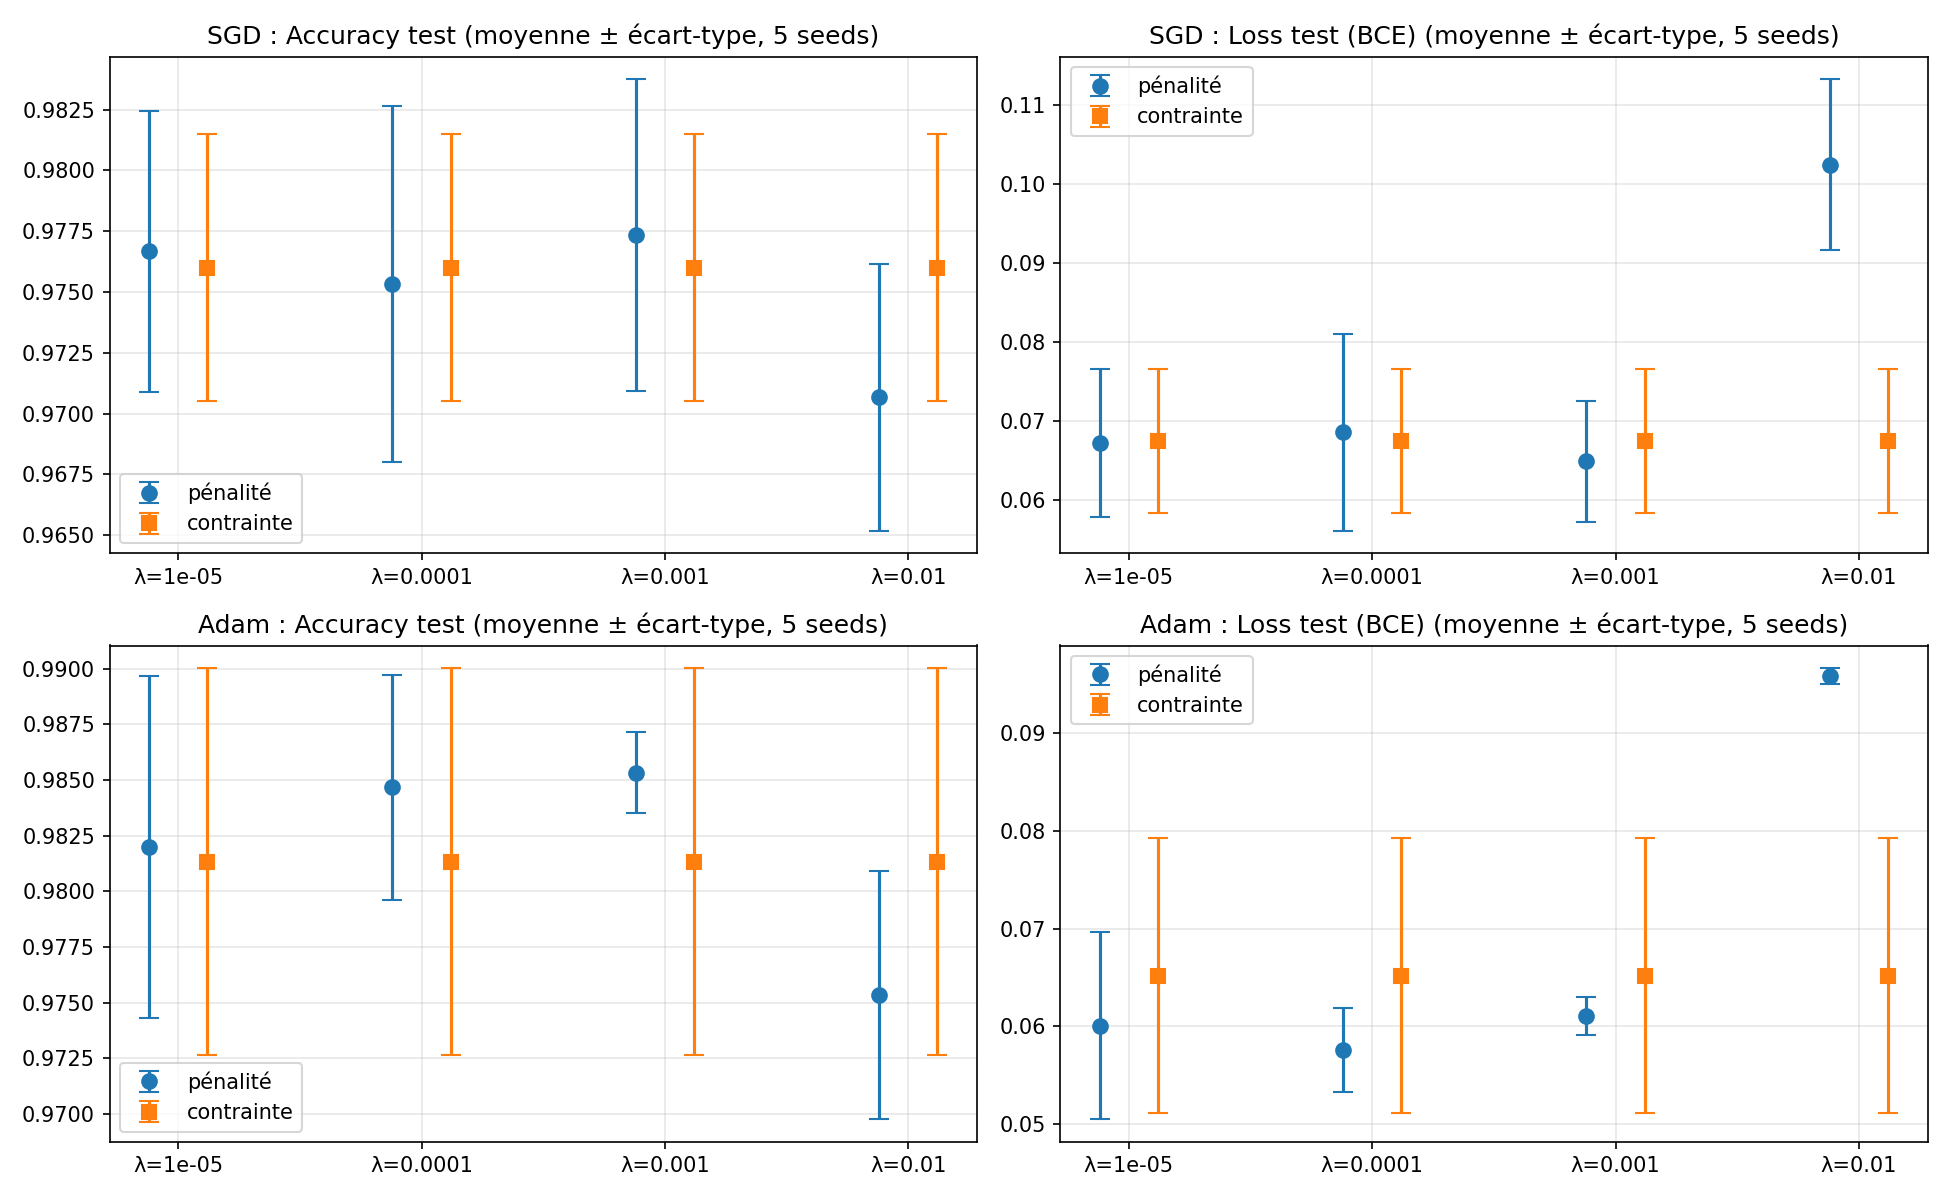

In [11]:
f1 = show_csv('F1_table.csv', index_col=[0, 1, 2])
show_fig('F1_trajectories.png', 1000)
show_csv('F1_stability.csv', index_col=[0, 1, 2], decimals=5)
show_fig('F1_test.png', 1000)

**Avec le gradient projeté (SGD), à norme égale, pénalité et contrainte donnent le même modèle.** La loss train est identique à 0.0005 près pour les quatre couples, et la loss de validation est égale ou très légèrement meilleure avec la contrainte (0.090 contre 0.091 pour $\lambda = 10^{-3}$). L'accuracy test diffère de moins d'un exemple sur 300 en moyenne. La stabilité, mesurée par la dispersion entre seeds, les oscillations et les pics de loss, est du même ordre. Les prédictions de validation coïncident à 99.7 % ou plus, alors que les paramètres diffèrent (distance relative de 0.06 à 0.38). Les deux méthodes trouvent donc la même fonction avec des paramètres différents. C'est attendu dans un réseau ReLU : multiplier les poids d'une couche par $a > 0$ et ceux de la couche suivante par $1/a$ ne change pas la fonction, mais change la répartition de la norme entre les couches.

**La différence porte sur le chemin suivi.** La pénalité laisse la norme dépasser sa valeur finale puis la ramène lentement : pour $\lambda = 10^{-3}$, elle monte à environ 8 vers l'époque 80 avant de redescendre à 7.1. La contrainte bloque la norme dès qu'elle atteint $R$, vers l'époque 8, et la garantit à chaque itération.

**Correspondance $\lambda \leftrightarrow \mu$.** Pour $\lambda = 10^{-2}$, le multiplicateur estimé vaut $\mu \approx 0.012$ pour les deux méthodes, proche de $\lambda$ comme le prévoient les conditions KKT. Pour les petits $\lambda$, l'estimation reste vers $7 \cdot 10^{-4}$ quel que soit $\lambda$ : le gradient en fin d'entraînement n'est pas aligné avec $\theta$, le point n'est pas stationnaire, et la correspondance n'est pas observable.

**Avec Adam, la contrainte échoue à cause de l'algorithme.** À norme égale, Adam suivi d'une projection donne une loss train nettement plus haute que la pénalité dès $\lambda \ge 10^{-3}$ (0.118 contre 0.079). Pourtant, le modèle pénalisé est un point admissible du problème contraint, avec une meilleure loss. En partant de ce point, SGD projeté garde la loss train à 0.079, alors qu'Adam projeté la fait monter à 0.105. L'explication est théorique. Adam fait le pas $\theta - \alpha D^{-1}\hat m$, où $D$ met chaque composante à l'échelle. Un point fixe d'Adam projeté vérifie donc $D^{-1}\nabla F = -c\,\theta$, alors qu'un point KKT vérifie $\nabla F = -\mu\,\theta$. Ces deux conditions ne coïncident que si $D$ est proportionnelle à l'identité. La projection euclidienne n'est cohérente qu'avec un pas de gradient non mis à l'échelle.

**Jalon J4.** La contrainte est active pour $\lambda = 10^{-3}$ et $10^{-2}$ (projection sur 26 % et 82 % des pas dès les premières époques) et pour $R = 0.5\,R_0$. Elle est inactive pour $R = 2\,R_0$ : la projection n'agit jamais et la trajectoire est identique, bit à bit, à l'entraînement non contraint.

### 8.5 Vérification avec PyTorch (partie G)

Un réseau PyTorch équivalent reçoit une copie des poids initiaux du modèle NumPy. Les deux modèles s'entraînent ensuite sur exactement les mêmes mini-batchs, en float64.

écart θ après 1 pas  après 1 époque  \
optimiseur précision PyTorch                                        
SGD        float64                   2.775558e-17    2.220446e-16   
           float32                   6.895591e-08    4.385129e-07   
Adam       float64                   5.551115e-17    2.220446e-16   
           float32                   5.386274e-08    2.022071e-07   

                              après 100 époques  après 500 époques  \
optimiseur précision PyTorch                                         
SGD        float64                 3.552714e-15       4.515832e-13   
           float32                 3.627630e-06       6.540199e-03   
Adam       float64                 1.019629e-12       9.514295e-10   
           float32                 1.266420e-05       1.083133e-04   

                              |Δ loss train| finale  |Δ loss val| finale  \
optimiseur précision PyTorch                                               
SGD        float64                     2.498002e-17         5.356826e-16   
           float32                     2.424496e-05         2.476242e-05   
Adam       float64                     3.147205e-14         1.209507e-12   
           float32                     2.912025e-08         3.863474e-07   

                              |Δ acc val| finale  temps NumPy / PyTorch  
optimiseur précision PyTorch                                             
SGD        float64                           0.0               0.344477  
           float32                           0.0               0.343701  
Adam       float64                           0.0               0.242755  
           float32                           0.0               0.226758

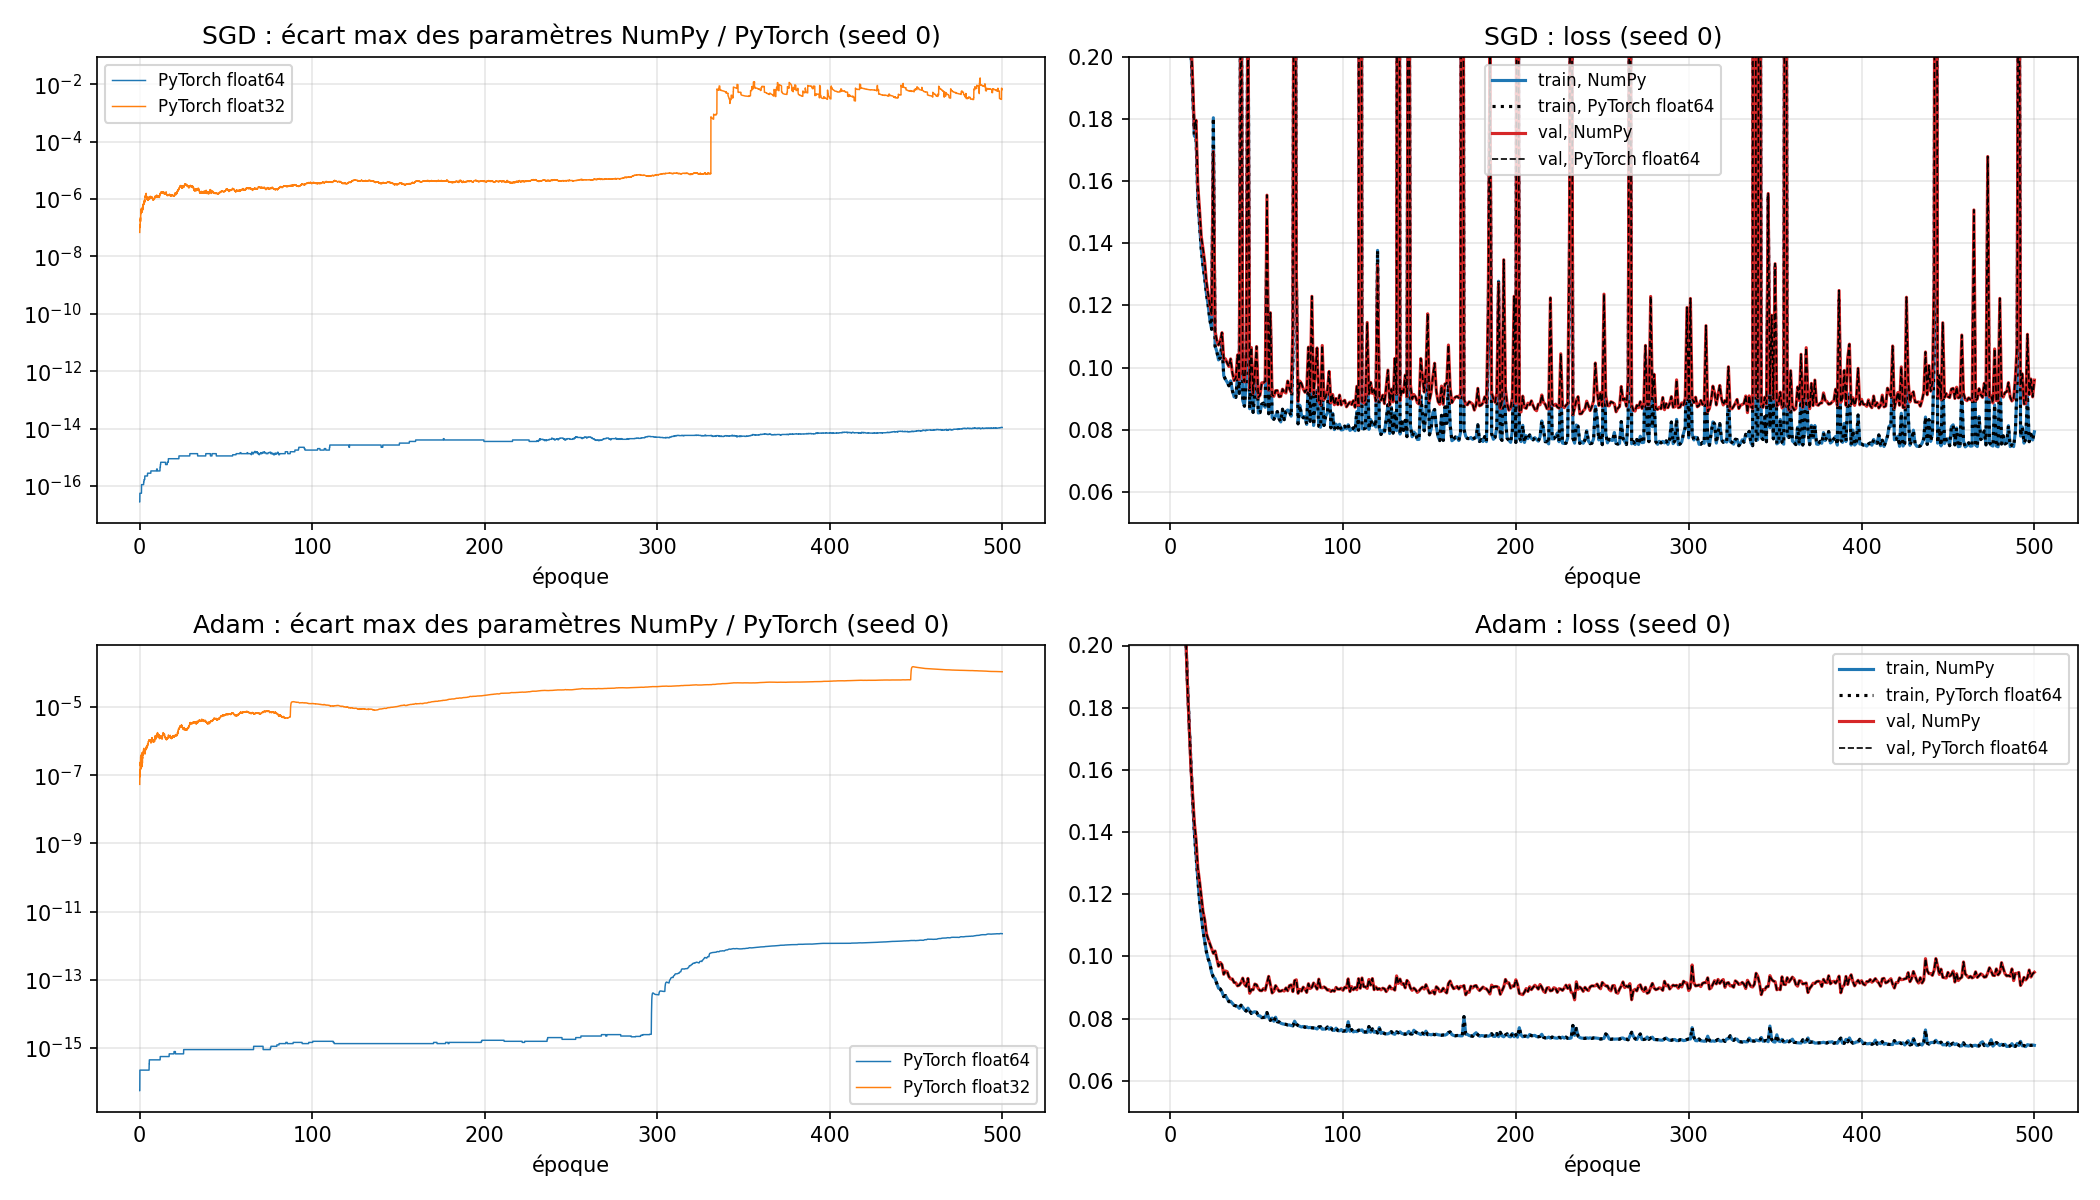

In [12]:
show_csv('G_table.csv', index_col=[0, 1], decimals=None)
show_fig('G_numpy_vs_torch.png', 1000)

Les gradients de notre rétropropagation coïncident avec ceux d'autograd à $5 \cdot 10^{-16}$ près. Avec les mêmes poids initiaux et les mêmes mini-batchs, l'écart entre les paramètres reste inférieur à $2 \cdot 10^{-12}$ pour SGD et à $2 \cdot 10^{-10}$ pour Adam après 500 époques, et les loss et l'accuracy finales sont identiques à 6 décimales. Ce petit écart vient de l'ordre des opérations : les arrondis diffèrent au dernier chiffre et se propagent lentement.

En float32, les paramètres finissent par différer nettement (écart de $10^{-2}$ pour SGD et d'environ 1 pour Adam), mais les loss restent très proches et l'accuracy est la même. L'entraînement est sensible aux petites perturbations, sans conséquence sur la qualité du modèle.

Pour le Momentum, `torch.optim.SGD(momentum=0.9, dampening=0.9)` initialise son buffer à $g_0$ au lieu de $(1-\beta)g_0$. Son premier pas est donc 10 fois plus grand que le nôtre. Une fois ce départ corrigé, les deux versions coïncident à $10^{-15}$ près. C'est une différence de convention, pas une erreur.

## 9. Discussion critique : réponses aux questions du sujet

**1. Quel optimiseur converge le plus rapidement ?**
À leur meilleur learning rate, les trois optimiseurs convergent à la même vitesse : 11 à 12.6 époques pour passer sous une loss train de 0.2. Avec des learning rates plus grands, Adam est le plus rapide (1.4 époque à $\alpha = 0.1$, 2 époques à $\alpha = 0.03$), devant Momentum (2.2 époques à $\alpha = 1$) et SGD (3 époques à $\alpha = 1$). Ces réglages rapides sont toutefois plus instables et généralisent moins bien.

**2. Quel optimiseur produit la meilleure performance de validation ?**
Momentum avec $\alpha = 0.1$ obtient la plus faible loss de validation (0.087) et la meilleure accuracy (0.971), devant Adam avec $\alpha = 0.003$ (0.088) et SGD avec $\alpha = 0.1$ (0.089). Les écarts, d'environ 0.001, sont plus petits que la variabilité entre seeds (0.002 à 0.006) : à leur meilleur réglage, les trois optimiseurs sont équivalents sur ce problème.

**3. Le meilleur résultat d'entraînement correspond-il au meilleur résultat de test ?**
Non. En partie C, la plus faible loss train est obtenue par Momentum avec $\alpha = 1$ (0.070), qui a l'une des moins bonnes validations (0.097) et un écart val − train de 0.026. En partie D, le modèle sans régularisation a la loss train la plus basse (0.068) mais la moins bonne loss test (0.065 ± 0.014), alors que l'early stopping et $L^2$, qui ajustent moins bien le train, obtiennent les meilleures loss test (0.060 et 0.061). Minimiser le risque empirique ne suffit pas à bien généraliser.

**4. À partir de quelle époque observe-t-on du sur-apprentissage ?**
Sans régularisation, la loss de validation atteint son minimum vers l'époque 127 en moyenne (entre 51 et 234 selon la seed), puis remonte alors que la loss train continue de baisser. L'écart val − train passe de 0.008 à l'époque 50 à 0.037 à l'époque 500. Il est à peine visible à 100 époques, d'où le budget de 500 époques.

**5. Quel effet produit $L^2$ sur $\|\theta\|$ et sur l'écart train/validation ?**
Quand $\lambda$ augmente, la norme et l'écart diminuent de façon monotone. Avec $\lambda = 10^{-3}$, la norme passe de 15.3 à 6.8 et l'écart de 0.037 à 0.006. Pour $\lambda \ge 10^{-2}$, la loss train remonte : le modèle sous-apprend.

**6. Quel effet produit le Dropout ?**
Il réduit l'écart val − train, surtout parce que le modèle s'ajuste moins bien au train. Il n'améliore la validation qu'au taux 0.1 (0.098 contre 0.105) et ne réduit pas la norme des poids (18.5). Il est moins efficace que $L^2$ sur ce problème, et sous-apprend à 0.5.

**7. Quel modèle est sélectionné par early stopping ?**
Avec $P = 20$, le modèle de l'époque 71 ± 24 (entre 46 et 96 selon la seed), après environ 91 époques effectuées sur 500. C'est aussi le modèle final retenu par la règle de sélection, avec la plus faible loss de validation (0.086). Sur le test, il est à égalité avec $L^2$.

**8. Quel effet produit une diminution de $R$ ?**
La loss train augmente quand $R$ diminue (0.066, 0.072 puis 0.094 de $R_0$ à $0.5\,R_0$). Une contrainte modérée améliore la validation (0.090 à $0.75\,R_0$ contre 0.104) en bloquant la norme au moment où le sur-apprentissage commence. Trop serrée, elle provoque du sous-apprentissage.

**9. Dans quelles expériences la contrainte est-elle active ?**
En E2, elle est active à $0.5\,R_0$ (projection sur 91 % des pas dès le début) et à $0.75\,R_0$ (à partir de l'époque 250 environ, sur 38 % des pas). Elle est inactive à $1.5\,R_0$ et $2\,R_0$, où la trajectoire est identique à l'entraînement non contraint. $R = R_0$ est un cas limite : la norme finale est sur le bord, mais la projection n'a jamais agi. En F, la contrainte est active pour $\lambda \ge 10^{-3}$.

**10. Quelle différence entre pénalisation $L^2$ et contrainte $\|\theta\| \le R$ ?**
À norme égale et avec le gradient projeté, les deux donnent des modèles équivalents en train, validation, test et stabilité, avec 99.7 % de prédictions identiques. La différence porte sur le chemin : la pénalité laisse la norme monter puis la ramène, alors que la contrainte la bloque et la garantit à chaque itération. Pour $\lambda = 10^{-2}$, le multiplicateur estimé ($\mu \approx 0.012$) est proche de $\lambda$, comme le prévoient les conditions KKT. En pratique, $R$ se lit directement comme une borne sur la norme, mais la contrainte exige un algorithme compatible avec la projection. La pénalité, elle, se combine avec n'importe quel optimiseur.

**11. Les résultats NumPy et PyTorch sont-ils cohérents ?**
Oui. Les gradients coïncident à $5 \cdot 10^{-16}$ près. SGD et Adam donnent les mêmes paramètres à $10^{-10}$ près après 500 époques en float64, et les mêmes loss et accuracy à 6 décimales. La seule différence, pour le Momentum, vient d'une convention d'initialisation de PyTorch, identifiée et corrigée.

**12. Quelles limites méthodologiques ?**
Les expériences reposent sur un seul découpage des données, avec des jeux de validation et de test de 300 points : un exemple représente 0.33 point d'accuracy, ce qui limite la portée des écarts observés. Le test semble plus facile que la validation, puisque sa loss est plus basse pour tous les modèles : l'écart entre test et validation ne mesure donc pas l'optimisme lié à la sélection des hyperparamètres. La loss de validation de l'early stopping est un minimum choisi sur la validation, donc légèrement optimiste. Les couples $(\lambda, R)$ de la partie F sont construits à partir des normes finales : ils comparent des solutions de même norme, pas des problèmes équivalents au sens théorique. Enfin, en E2, j'ai utilisé Adam suivi d'une projection, pour garder le même optimiseur que la référence. La partie F montre que cette variante résout moins bien le problème contraint que le gradient projeté avec SGD. Les loss train de E2 surestiment donc un peu l'effet de la contrainte, mais les tendances restent les mêmes.

## 10. Conclusion

Le réseau construit en NumPy est correct : ses gradients sont validés par différences finies et coïncident avec ceux de PyTorch à la précision machine, et ses optimiseurs reproduisent exactement ceux de PyTorch.

Sur ce problème, l'optimiseur compte moins que son réglage. À leur meilleur learning rate, SGD, Momentum et Adam convergent à la même vitesse et généralisent de la même façon. Un learning rate trop grand accélère le début de l'entraînement mais dégrade la généralisation.

Sans contrôle, le réseau sur-apprend à partir d'une centaine d'époques. La pénalité $L^2$ et l'early stopping corrigent ce défaut le mieux. Leur principal apport est la stabilité des résultats d'une initialisation à l'autre, plus qu'un gain de performance moyen, qui reste dans le bruit sur 300 points de test.

La contrainte explicite $\|\theta\|_2 \le R$, résolue par gradient projeté, donne les mêmes modèles que la pénalité à norme égale. Elle contrôle directement la norme à chaque itération. Le choix entre pénalité et contrainte est donc surtout pratique, à une condition que le projet a mise en évidence : l'algorithme doit respecter la géométrie de la projection. Le gradient projeté le fait, Adam suivi d'une projection ne le fait pas.

## Annexe : reproductibilité

Les résultats se reproduisent en exécutant les notebooks dans l'ordre : `01_data`, `02_layers_forward`, `03_backward_gradcheck`, `04_optimizers`, `05_comparison_optimizers`, `06_regularization`, `07_constraints`, `08_penalty_vs_constraint`, `09_pytorch_check`, puis ce notebook. Les données sont générées avec la graine 42, et les expériences utilisent les seeds 0 à 4. Les tableaux (`.csv`) et les figures (`.png`) sont enregistrés dans `results/`. Les cellules d'évaluation sur le test (06 et 08) refusent de s'exécuter deux fois dans la même session, pour garantir une seule évaluation.